# Analyze scGraph and the advantage PCA-based integrations have

In [1]:
import numpy as np
import pickle
import pandas as pd
import scanpy as sc
import anndata as ad
import scipy
from scipy.cluster.hierarchy import linkage, leaves_list
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
import sklearn
from itertools import combinations
import colorcet as cc
from sklearn.covariance import MinCovDet
from scipy.stats import chi2
import math
import statsmodels.api as sm

import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

import os
import sys
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/')
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scripts/project_utils/')
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"

mm_s = pd.read_csv('../scib/scib/resources/s_genes_tirosh.txt', header=None, index_col=0).index.to_numpy()
mm_g2m = pd.read_csv('../scib/scib/resources/g2m_genes_tirosh.txt', header=None, index_col=0).index.to_numpy()

hg_s = pd.read_csv('../scib/scib/resources/s_genes_tirosh_hm.txt', header=None, index_col=0).index.to_numpy()
hg_g2m = pd.read_csv('../scib/scib/resources/g2m_genes_tirosh_hm.txt', header=None, index_col=0).index.to_numpy()

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
import scib
from scib.metrics import *
from analysis_helpers import *

from scib.metrics.sc_graph import scGraph, calculate_trimmed_means, compute_classwise_distances

In [3]:
df_full = pd.read_csv('../results/spreadsheets/augmented_metrics_v1.csv', index_col=0)
df_full['Dataset'] = df_full['Dataset'].replace({
    'nph_cerebellum': 'nhp_cerebellum',
    'nph_liver': 'nhp_liver'
})
pivoted_df = df_full.pivot(index=['Dataset', 'Integration'], columns='Metric', values='Value')

runs = pd.read_csv('../results/spreadsheets/all_integrations.csv', index_col=0)

In [5]:
dataset_keys = {
    "scib_sim1": {
        "celltype_keys": ["Group"],
        "batch_keys": ["Batch"]
    },
    "scib_sim2": {
        "celltype_keys": ["Group"],
        "batch_keys": ["Batch"]
    },
    "human_pancreas": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["tech"]
    },
    "human_lung": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["batch"]
    },
    "neurips_bmmc": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["batch"]
    },
    "seurat_pbmc": {
        "celltype_keys": ["celltype.l2"],
        "batch_keys": ["donor"]
    },
    "human_brain_cell_atlas": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["donor_id", "ROIGroup"]
    },
    "human_fetal_gut": {
        "celltype_keys": ["cell_name_detailed"],
        "batch_keys": ["Donor_id", "Organ", "Sample"]
    },
    "human_liver_time": {
        "celltype_keys": ["time"],
        "batch_keys": ["batch"]
    },
    "pan_cancer_dc": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["dataset_id", "cancer_type"]
    },
    "human_eoe": {
        "celltype_keys": ["cell_type_anno"],
        "batch_keys": ["donor_id"]
    },
    "pan_cancer_b": {
        "celltype_keys": ["clusters"],
        "batch_keys": ["study"]
    },
    "human_retina_organoid_tissue": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["sample_id", "tissue"]
    },
    "mouse_regulatory_T": {
        "celltype_keys": ["cell.type"],
        "batch_keys": ["method", "orig.ident"]
    },
    "human_adipose": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["technology", "individual"]
    },
    "tian_multitech": {
        "celltype_keys": ["cell_line"],
        "batch_keys": ["tech"]
    },
    "nhp_liver": {
        "celltype_keys": ["Celltype"],
        "batch_keys": ["Sample"]
    },
    "nhp_cerebellum": {
        "celltype_keys": ["Celltype"],
        "batch_keys": ["Sample"]
    },
    "tabula_muris_lung": {
        "celltype_keys": ["cell_ontology_id"],
        "batch_keys": ["mouse.id", "tech"]
    },
    "human_pbmc_sequencing_techs": {
        "celltype_keys": ["CellType"],
        "batch_keys": ["Method", "Experiment"]
    },
    "mouse_retina": {
        "celltype_keys": ["CellType"],
        "batch_keys": ["dataset"]
    },
    "mouse_mammary": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["BATCH"]
    },
    "macaque_retina": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["BATCH"]
    },
    "human_heart": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["DonorID", "Tissue"]
    },
    "mouse_cortex_sequencing_techs": {
        "celltype_keys": ["CellType"],
        "batch_keys": ["Method", "Experiment"]
    },
    "jurkat_293t": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["dataset"]
    },
    "3_5_pbmc": {
        "celltype_keys": ["celltype"],
        "batch_keys": ["batch"]
    },
    "cellranger_versions": {
        "celltype_keys": ["cell_type"],
        "batch_keys": ["batch"]
    }
}


## Sensitivity to the number of PCs

In [4]:
adata = sc.read('../data/neurips_bmmc.h5ad')

In [5]:
d = runs[runs.name.str.contains('neurips_bmmc') & runs.name.str.contains('scvi')].iloc[0]['workdir']
adata_int = sc.read(f"{d}/save_dir/adata.h5ad")
batch_col = adata_int.obs.columns[0]
celltype_col = adata_int.obs.columns[-11]

if adata_int.X is None:
    adata_int = ad.AnnData(
        X=adata.X,
        obs=adata_int.obs,
        var=adata.var,
        uns=adata_int.uns,
        obsm=adata_int.obsm,
        varm=adata_int.varm,
        obsp=adata_int.obsp,
        varp=adata.varp,
        layers=adata.layers,
)

adata_int

AnnData object with n_obs × n_vars = 90261 × 13953
    obs: 'batch', 'cell_type', 'cluster_0.2', 'cluster_0.4', 'cluster_0.6', 'cluster_0.8', 'cluster_1.0', 'cluster_1.2', 'cluster_1.4', 'cluster_1.6', 'cluster_1.8', 'cluster_2.0'
    var: 'feature_types', 'gene_id', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'cluster_0.2', 'cluster_0.4', 'cluster_0.6', 'cluster_0.8', 'cluster_1.0', 'cluster_1.2', 'cluster_1.4', 'cluster_1.6', 'cluster_1.8', 'cluster_2.0', 'neighbors'
    obsm: 'X_integration', 'X_umap'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [6]:
sg = scGraph(adata_int, batch_col, celltype_col)
sg.preprocess()
sg.process_batches()
sg.calculate_consensus()

TypeError: scGraph.__init__() missing 1 required positional argument: 'method'

In [45]:
sg1 = scGraph(adata_int, batch_col, celltype_col, pca_comps=11)
sg1.preprocess()
sg1.process_batches()
sg1.calculate_consensus()

Processing batches, calcualte centroids and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:01<00:00,  1.78it/s]


In [46]:
sg2 = scGraph(adata_int, batch_col, celltype_col, pca_comps=50)
sg2.preprocess()
sg2.process_batches()
sg2.calculate_consensus()

Processing batches, calcualte centroids and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:01<00:00,  1.09it/s]


In [46]:
np.mean(sg1._collect_pca_['CB'].to_numpy() - sg._collect_pca_['CB'].to_numpy())

np.float64(0.0023897363985703702)

In [47]:
np.mean(sg1._collect_pca_['BM'].to_numpy() - sg._collect_pca_['BM'].to_numpy())

np.float64(0.016718353130947786)

In [48]:
np.mean(sg2._collect_pca_['CB'].to_numpy() - sg._collect_pca_['CB'].to_numpy())

np.float64(0.03128213088867018)

In [49]:
np.mean(sg2._collect_pca_['BM'].to_numpy() - sg._collect_pca_['BM'].to_numpy())

np.float64(0.120646423044234)

In [60]:
scipy.stats.pearsonr(sg._collect_pca_['BM'].to_numpy().flatten(), sg1._collect_pca_['BM'].to_numpy().flatten()), \
    scipy.stats.spearmanr(sg._collect_pca_['BM'].to_numpy().flatten(), sg1._collect_pca_['BM'].to_numpy().flatten())

(PearsonRResult(statistic=np.float64(0.9954197294548119), pvalue=np.float64(1.1290161774083028e-146)),
 SignificanceResult(statistic=np.float64(0.988935115517394), pvalue=np.float64(1.4193455342440718e-119)))

In [61]:
scipy.stats.pearsonr(sg._collect_pca_['CB'].to_numpy().flatten(), sg._collect_pca_['CB'].to_numpy().flatten()), \
    scipy.stats.spearmanr(sg._collect_pca_['CB'].to_numpy().flatten(), sg1._collect_pca_['CB'].to_numpy().flatten())

(PearsonRResult(statistic=np.float64(0.9999442281244246), pvalue=np.float64(5.779102099652255e-47)),
 SignificanceResult(statistic=np.float64(0.9992187500000002), pvalue=np.float64(8.783109047144133e-34)))

In [62]:
scipy.stats.pearsonr(sg._collect_pca_['BM'].to_numpy().flatten(), sg2._collect_pca_['BM'].to_numpy().flatten()), \
    scipy.stats.spearmanr(sg._collect_pca_['BM'].to_numpy().flatten(), sg2._collect_pca_['BM'].to_numpy().flatten())

(PearsonRResult(statistic=np.float64(0.8873100712075166), pvalue=np.float64(1.39591378983194e-49)),
 SignificanceResult(statistic=np.float64(0.8176557332195996), pvalue=np.float64(7.238422028328015e-36)))

In [64]:
scipy.stats.pearsonr(sg._collect_pca_['CB'].to_numpy().flatten(), sg2._collect_pca_['CB'].to_numpy().flatten()), \
    scipy.stats.spearmanr(sg._collect_pca_['CB'].to_numpy().flatten(), sg2._collect_pca_['CB'].to_numpy().flatten())

(PearsonRResult(statistic=np.float64(0.9932923051829596), pvalue=np.float64(4.6741658726052036e-23)),
 SignificanceResult(statistic=np.float64(0.9929687500000001), pvalue=np.float64(8.022407390708543e-23)))

In [51]:
res_df = pd.DataFrame(columns=["Rank-PCA", "Corr-PCA", "Corr-Weighted"])
adata_df = sg.adata_concensus('X_integration')
_row_df = pd.DataFrame(
    {
        "Rank-PCA": sg.rank_diff(adata_df, sg.concensus_df_pca)
        .mean()
        .values,
        "Corr-PCA": sg.corr_diff(adata_df, sg.concensus_df_pca)
        .mean()
        .values,
        "Corr-Weighted": sg.corrw_diff(adata_df, sg.concensus_df_pca)
        .mean()
        .values,
    },
    index=['X_integration'],
)
res_df = pd.concat([res_df, _row_df], axis=0, sort=False)
res_df

/scratch-ssd/slurm-jobs/yinian/1778040/ipykernel_3148503/928958897.py:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  res_df = pd.concat([res_df, _row_df], axis=0, sort=False)


,Rank-PCA,Corr-PCA,Corr-Weighted
X_integration,0.418998,0.593241,0.424354


In [52]:
res_df = pd.DataFrame(columns=["Rank-PCA", "Corr-PCA", "Corr-Weighted"])
adata_df = sg1.adata_concensus('X_integration')
_row_df = pd.DataFrame(
    {
        "Rank-PCA": sg1.rank_diff(adata_df, sg1.concensus_df_pca)
        .mean()
        .values,
        "Corr-PCA": sg1.corr_diff(adata_df, sg1.concensus_df_pca)
        .mean()
        .values,
        "Corr-Weighted": sg1.corrw_diff(adata_df, sg1.concensus_df_pca)
        .mean()
        .values,
    },
    index=['X_integration'],
)
res_df = pd.concat([res_df, _row_df], axis=0, sort=False)
res_df

/scratch-ssd/slurm-jobs/yinian/1778040/ipykernel_3148503/3087573531.py:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  res_df = pd.concat([res_df, _row_df], axis=0, sort=False)


,Rank-PCA,Corr-PCA,Corr-Weighted
X_integration,0.453963,0.629004,0.462989


In [53]:
res_df = pd.DataFrame(columns=["Rank-PCA", "Corr-PCA", "Corr-Weighted"])
adata_df = sg2.adata_concensus('X_integration')
_row_df = pd.DataFrame(
    {
        "Rank-PCA": sg2.rank_diff(adata_df, sg2.concensus_df_pca)
        .mean()
        .values,
        "Corr-PCA": sg2.corr_diff(adata_df, sg2.concensus_df_pca)
        .mean()
        .values,
        "Corr-Weighted": sg2.corrw_diff(adata_df, sg2.concensus_df_pca)
        .mean()
        .values,
    },
    index=['X_integration'],
)
res_df = pd.concat([res_df, _row_df], axis=0, sort=False)
res_df

/scratch-ssd/slurm-jobs/yinian/1778040/ipykernel_3148503/3761547926.py:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  res_df = pd.concat([res_df, _row_df], axis=0, sort=False)


,Rank-PCA,Corr-PCA,Corr-Weighted
X_integration,0.547203,0.774737,0.529526


## How do rankings of integrations change using different number of PCs

In [6]:
dirs = runs[runs.name.str.contains('mouse_retina')]

In [7]:
scgraph_10_res = []
scgraph_15_res = []
scgraph_20_res = []

for ind, d in dirs.iterrows():
    adata_int = sc.read(f"{d['workdir']}/save_dir/adata.h5ad")
    batch_col = adata_int.obs.columns[0]
    celltype_col = adata_int.obs.columns[-11]

    if adata_int.X is None:
        adata_int = ad.AnnData(
            X=adata.X,
            obs=adata_int.obs,
            var=adata.var,
            uns=adata_int.uns,
            obsm=adata_int.obsm,
            varm=adata_int.varm,
            obsp=adata_int.obsp,
            varp=adata.varp,
            layers=adata.layers,
    )
        
    scgraph_10_res.append((d['integration'], scgraph(adata_int, batch_col, celltype_col, EMB_KEY, pca_comps=10)))
    scgraph_15_res.append((d['integration'], scgraph(adata_int, batch_col, celltype_col, EMB_KEY, pca_comps=15)))
    scgraph_20_res.append((d['integration'], scgraph(adata_int, batch_col, celltype_col, EMB_KEY, pca_comps=20)))

Processing batches, calcualte centroids and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:01<00:00,  1.73it/s]
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/sc_graph.py:206: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  res_df = pd.concat([res_df, _row_df], axis=0, sort=False)


Processing batches, calcualte centroids and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:01<00:00,  1.61it/s]
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/sc_graph.py:206: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  res_df = pd.concat([res_df, _row_df], axis=0, sort=False)


Processing batches, calcualte centroids and pairwise distances


...

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:01<00:00,  1.81it/s]
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/sc_graph.py:206: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  res_df = pd.concat([res_df, _row_df], axis=0, sort=False)


Processing batches, calcualte centroids and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:01<00:00,  1.67it/s]
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/sc_graph.py:206: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  res_df = pd.concat([res_df, _row_df], axis=0, sort=False)


Processing batches, calcualte centroids and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:01<00:00,  1.62it/s]
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/sc_graph.py:206: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  res_df = pd.concat([res_df, _row_df], axis=0, sort=False)


In [75]:
scgraph_50_res = []

for ind, d in dirs.iterrows():
    adata_int = sc.read(f"{d['workdir']}/save_dir/adata.h5ad")
    batch_col = adata_int.obs.columns[0]
    celltype_col = adata_int.obs.columns[-11]

    if adata_int.X is None:
        adata_int = ad.AnnData(
            X=adata.X,
            obs=adata_int.obs,
            var=adata.var,
            uns=adata_int.uns,
            obsm=adata_int.obsm,
            varm=adata_int.varm,
            obsp=adata_int.obsp,
            varp=adata.varp,
            layers=adata.layers,
    )
        
    scgraph_50_res.append((d['integration'], scgraph(adata_int, batch_col, celltype_col, EMB_KEY, pca_comps=50)))

Processing batches, calcualte centroids and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:02<00:00,  1.04s/it]
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/sc_graph.py:206: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  res_df = pd.concat([res_df, _row_df], axis=0, sort=False)


Processing batches, calcualte centroids and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:01<00:00,  1.03it/s]
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/sc_graph.py:206: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  res_df = pd.concat([res_df, _row_df], axis=0, sort=False)


Processing batches, calcualte centroids and pairwise distances


...

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:01<00:00,  1.08it/s]
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/sc_graph.py:206: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  res_df = pd.concat([res_df, _row_df], axis=0, sort=False)


Processing batches, calcualte centroids and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:01<00:00,  1.07it/s]
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/sc_graph.py:206: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  res_df = pd.concat([res_df, _row_df], axis=0, sort=False)


Processing batches, calcualte centroids and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:01<00:00,  1.08it/s]
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/sc_graph.py:206: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  res_df = pd.concat([res_df, _row_df], axis=0, sort=False)


In [76]:
scgraph_10_df = pd.DataFrame([(x[0], x[1][0]['X_integration']) for x in scgraph_10_res], columns=['Integration', 'Value_10'])
scgraph_15_df = pd.DataFrame([(x[0], x[1][0]['X_integration']) for x in scgraph_15_res], columns=['Integration', 'Value_15'])
scgraph_20_df = pd.DataFrame([(x[0], x[1][0]['X_integration']) for x in scgraph_20_res], columns=['Integration', 'Value_20'])
scgraph_50_df = pd.DataFrame([(x[0], x[1][0]['X_integration']) for x in scgraph_50_res], columns=['Integration', 'Value_50'])

In [77]:
sub_df = df_full[(df_full['Dataset'] == 'mouse_retina') & (df_full['Metric'] == 'scgraph')]
sub_df = sub_df[~sub_df['Value'].isna()][['Integration', 'Value']]

In [78]:
df_merged = scgraph_10_df.merge(scgraph_15_df, on='Integration').merge(scgraph_20_df, on='Integration').merge(scgraph_50_df, on='Integration')

In [238]:
df_merged.to_csv('../results/metric_interrogation/scgraph.csv')

In [85]:
df_merged['Integration'] = df_merged['Integration'].str[:-2]

/tmp/ipykernel_3381759/2514119200.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_long['Rank'] = df_long.groupby('Metric_Level')['Score'].rank(ascending=False, method='min')
/tmp/ipykernel_3381759/2514119200.py:47: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['10D PCA', '15D PCA', '20D PCA', '50D PCA'])


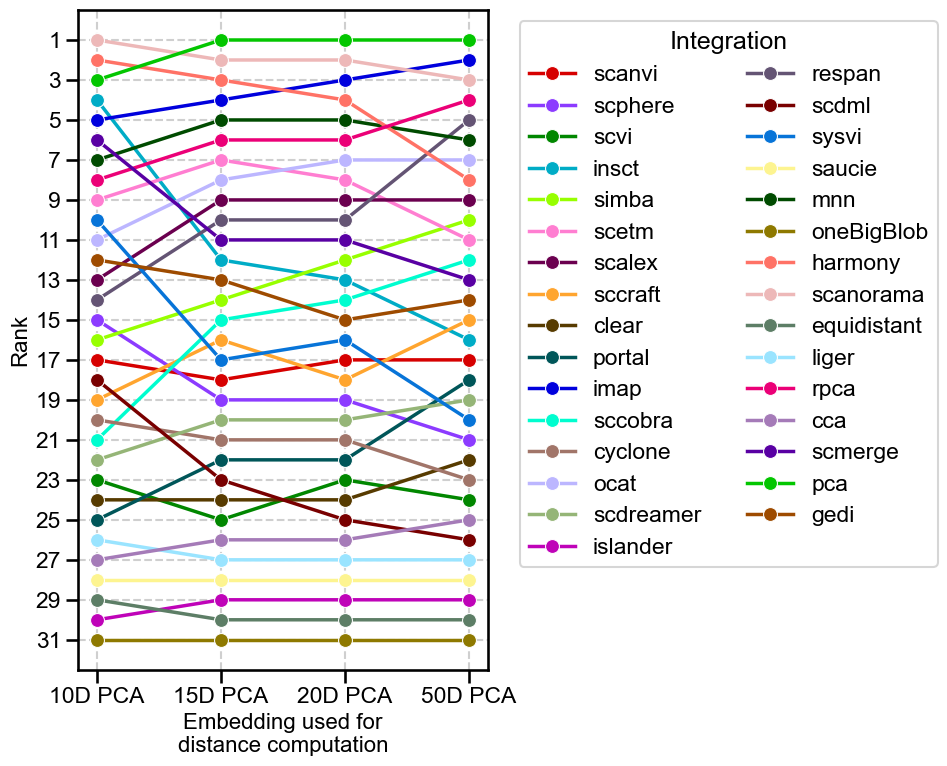

In [87]:
value_vars = ['Value_10', 'Value_15', 'Value_20', 'Value_50']
df_long = df_merged.melt(
    id_vars=['Integration'], 
    value_vars=value_vars, 
    var_name='Metric_Level', 
    value_name='Score'
)

# 2. Set categorical order for the x-axis
df_long['Metric_Level'] = pd.Categorical(
    df_long['Metric_Level'], 
    categories=value_vars, 
    ordered=True
)

df_long['Rank'] = df_long.groupby('Metric_Level')['Score'].rank(ascending=False, method='min')

plt.figure(figsize=(10, 8))
unique_integrations = df_long['Integration'].unique()
palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

# 5. Plot Bump Chart
ax = sns.lineplot(
    data=df_long, 
    x='Metric_Level', 
    y='Rank', 
    hue='Integration', 
    marker='o', 
    markersize=10,
    linewidth=2.5, 
    palette=palette
)

ax.set_xlabel('Embedding used for\ndistance computation', fontsize=16)
ax.set_ylabel('Rank', fontsize=16)

# Invert Y-axis so Rank 1 is at the top
ax.invert_yaxis()

# Ensure Y-axis only shows integer ranks
ax.set_yticks(range(1, len(unique_integrations) + 1, 2))
ax.set_xticklabels(['10D PCA', '15D PCA', '20D PCA', '50D PCA'])

# Add grid for readability
ax.grid(True, linestyle='--', alpha=0.6)

# Move legend outside the plot
plt.legend(title='Integration', bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2)

plt.tight_layout()
plt.show()

/tmp/ipykernel_3381759/3793579733.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['10D PCA', '15D PCA', '20D PCA', '50D PCA'])


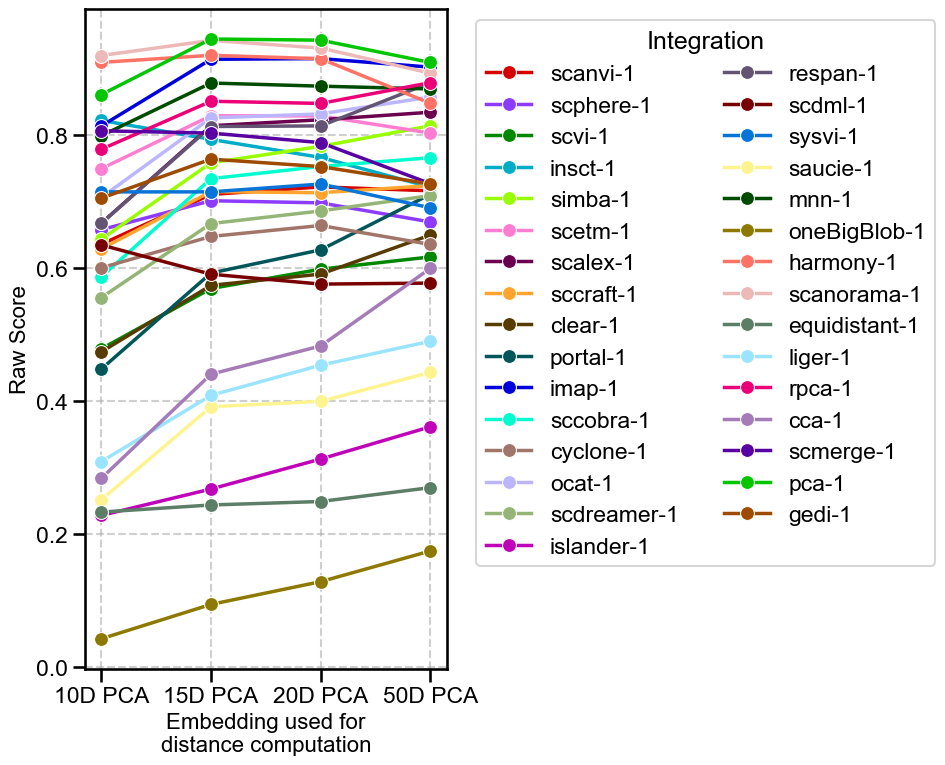

In [81]:
value_vars = ['Value_10', 'Value_15', 'Value_20', 'Value_50']
df_long = df_merged.melt(
    id_vars=['Integration'], 
    value_vars=value_vars, 
    var_name='Metric_Level', 
    value_name='Score'
)

df_long['Metric_Level'] = pd.Categorical(
    df_long['Metric_Level'], 
    categories=value_vars, 
    ordered=True
)

plt.figure(figsize=(10, 8))
unique_integrations = df_long['Integration'].unique()

ax = sns.lineplot(
    data=df_long, 
    x='Metric_Level', 
    y='Score',          # Changed from 'Rank' to 'Score'
    hue='Integration', 
    marker='o', 
    markersize=10,
    linewidth=2.5, 
    palette=palette
)

ax.set_xlabel('Embedding used for\ndistance computation', fontsize=16)
ax.set_ylabel('Raw Score', fontsize=16) # Updated Label

ax.set_xticklabels(['10D PCA', '15D PCA', '20D PCA', '50D PCA'])
ax.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Integration', bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2)

plt.tight_layout()
plt.show()

In [66]:
scipy.stats.spearmanr(df_merged['Value_10'], df_merged['Value_15'])

SignificanceResult(statistic=np.float64(0.9370967741935484), pvalue=np.float64(8.664444607671386e-15))

In [67]:
scipy.stats.spearmanr(df_merged['Value_10'], df_merged['Value_20'])

SignificanceResult(statistic=np.float64(0.9254032258064517), pvalue=np.float64(9.513740529108697e-14))

In [74]:
scipy.stats.spearmanr(df_merged['Value_15'], df_merged['Value_20'])

SignificanceResult(statistic=np.float64(0.9943548387096777), pvalue=np.float64(8.236439375385543e-30))

In [82]:
scipy.stats.spearmanr(df_merged['Value_10'], df_merged['Value_50'])

SignificanceResult(statistic=np.float64(0.8395161290322581), pvalue=np.float64(3.5828775802477248e-09))

In [83]:
scipy.stats.spearmanr(df_merged['Value_15'], df_merged['Value_50'])

SignificanceResult(statistic=np.float64(0.9649193548387097), pvalue=np.float64(2.179986270797019e-18))

In [84]:
scipy.stats.spearmanr(df_merged['Value_20'], df_merged['Value_50'])

SignificanceResult(statistic=np.float64(0.9725806451612905), pvalue=np.float64(6.428484421380406e-20))

In [88]:
counter = sc.read('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/work/93/7639bded6a57be53204f3fe45982f1/save_dir/adata.h5ad')

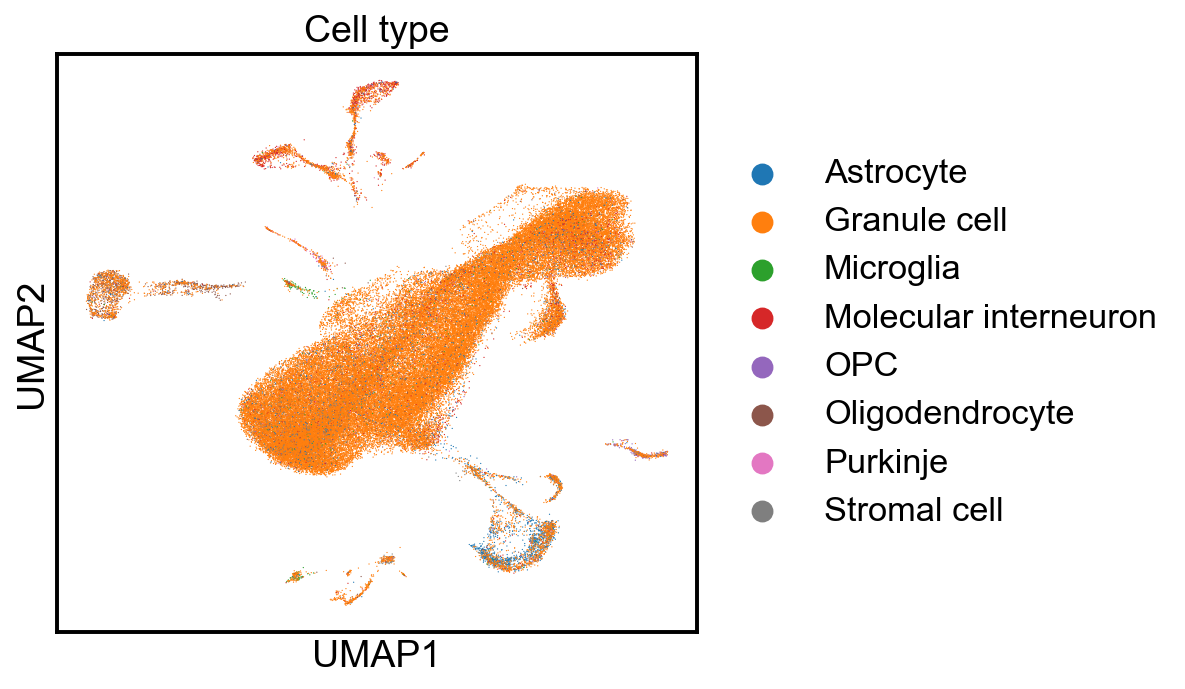

In [100]:
with plt.rc_context({'figure.figsize': (5.5, 5), 'figure.dpi': 150}):
    sc.pl.umap(counter, color=[ 'Celltype'], wspace=0.3, title=[ 'Cell type'])

## Prove PCA-related integrations perform the best?

In [6]:
df = df_full.copy()

In [7]:
bio = ['agree', 'ami', 'ari', 'arif', 'awc', 'bami', 'bari', 'bvm', 'casw', 'ccc', 'cch', 'ccent', 'clisi',
       'cnent', 'comp', 'corrmse', 'cdbi', 'f1', 'fknn', 'flogreg', 'fmi', 'gc', 'homo', 'isoasw', 'isof1',
       'jacc', 'ksim', 'ldfdiff', 'mcc', 'morani', 'nmi', 'nmif', 'nnmap', 'ocs', 'purity', 'rknn',
       'scgraph',  'traj', 'vi', 'vm', 'clustasw', 'clustdbi', 'clustch'
       'scgraphm', 'scgraphp'] # Augmentations

In [8]:
df = df[~df.Integration.isin(['islander-1', 'oneBigBlob-1', 'equidistant-1', 'pca-1'])]
df = df[df.Metric.isin(bio)]

In [9]:
pca_based = ['harmony-1', 'scanorama-1', 'rpca-1', 'mnn-1']
knn = ['ccent', 'homo', 'jacc', 'purity', 'nmif', 'arif', 'bknn', 'fknn', 'mcc', 'f1', 'nnmap', 'cnent', 'ocs', 'ksim', 'clisi']
df['Rank'] = df.groupby(['Dataset', 'Metric'])['Value'].rank(ascending=True, method='min', pct=True)

df['is_pca_based'] = df['Integration'].isin(pca_based)
df['is_target_metric'] = df['Metric'].isin(['scgraph'])

sub_df1 = df[df['Metric'].isin(['corrmse', 'agree', 'traj', 'morani', 'rknn', 'ccc', 'scgraph', 'ldfdiff'])]
sub_df2 = df[~df['Metric'].isin(knn)]

In [10]:
sub_df1_agg = sub_df1.groupby(['Dataset', 'is_pca_based'])['Rank'].mean().reset_index()
df_pivot1 = sub_df1_agg.pivot(index='Dataset', columns='is_pca_based', values='Rank')
df_pivot1['Difference'] = df_pivot1[False] - df_pivot1[True]

sub_df2_agg = sub_df2.groupby(['Dataset', 'is_pca_based'])['Rank'].mean().reset_index()
df_pivot2 = sub_df2_agg.pivot(index='Dataset', columns='is_pca_based', values='Rank')
df_pivot2['Difference'] = df_pivot2[False] - df_pivot2[True]

In [11]:
df_pivot1[True]

Dataset
3_5_pbmc                        0.851732
cellranger_versions             0.849790
human_adipose                   0.761828
human_brain_cell_atlas          0.630515
human_eoe                       0.676779
human_fetal_gut                 0.776651
human_heart                     0.682540
human_lung                      0.672811
human_pancreas                  0.803061
human_pbmc_seq_techs            0.825000
human_retina_organoid_tissue    0.655172
jurkat_293t                     0.873737
macaque_retina                  0.681070
mouse_cortex_seq_techs          0.844907
mouse_mammary                   0.796474
mouse_regulatory_T              0.799172
mouse_retina                    0.853175
neurips_bmmc                    0.833333
nhp_cerebellum                  0.768519
nhp_liver                       0.864198
pan_cancer_b                    0.762634
pan_cancer_dc                   0.514739
scib_sim1                       0.803571
scib_sim2                       0.822917
seurat_p

In [12]:
stat, p_value = scipy.stats.wilcoxon(df_pivot1[True], df_pivot2[True], alternative='less')
stat, p_value

(np.float64(378.0), np.float64(1.0))

In [13]:
stat, p_value = scipy.stats.wilcoxon(df_pivot1['Difference'], df_pivot2['Difference'], alternative='greater')
stat, p_value

(np.float64(0.0), np.float64(1.0))

In [14]:
df_pivot = df_pivot1.join(df_pivot2, lsuffix='_1', rsuffix='_2')

/tmp/ipykernel_2962959/3464096263.py:40: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


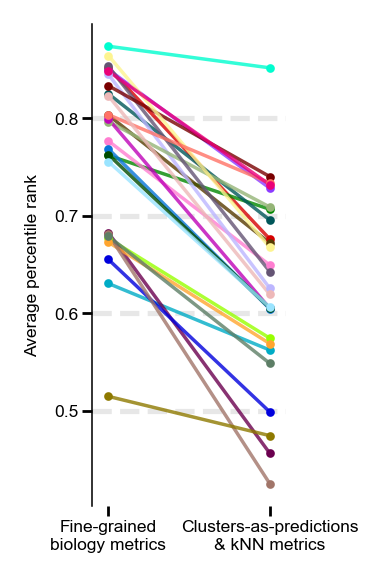

In [16]:
data = []
for i, row in df_pivot.iterrows():
    data.append((i, row['True_1'], row['True_2']))

palette = cc.glasbey
with plt.rc_context({'figure.dpi': 250}):
    fig, ax = plt.subplots(figsize=(1, 2.5))

    for i, (name, x_val, y_val) in enumerate(data):
        color = palette[i % len(palette)]

        ax.plot([0, 1], [x_val, y_val], color=color, linewidth=1, markersize=1, alpha=0.8, label=name)
        ax.scatter([0, 1], [x_val, y_val], color=color, s=1, zorder=3)
    ax.tick_params(axis='x', labelsize=12)
    ax.tick_params(axis='y', labelsize=12)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Fine-grained\nbiology metrics', 'Clusters-as-predictions\n& kNN metrics'], fontsize=5, fontweight='bold')
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylabel("Average percentile rank", fontsize=5)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.tick_params(axis='both', which='major', width=.8, length=3, labelsize=5, pad=1)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)
    ax.yaxis.grid(True, linestyle='--', alpha=0.3)

    plt.tight_layout()
    plt.savefig('../publication_figures/pca_based_knn.png', dpi=250, bbox_inches='tight')
    plt.show()

In [15]:
pca_based = ['harmony-1', 'scanorama-1', 'rpca-1', 'mnn-1']
cluster_label = ['bari', 'bami', 'bvm', 'ari','ami', 'nmi','vm','awc', 'vi', 'fmi']
df['Rank'] = df.groupby(['Dataset', 'Metric'])['Value'].rank(ascending=True, method='min', pct=True)

df['is_pca_based'] = df['Integration'].isin(pca_based)
df['is_target_metric'] = df['Metric'].isin(['scgraph'])

sub_df1 = df[df['Metric'].isin(['corrmse', 'agree', 'traj', 'morani', 'rknn', 'ccc', 'scgraph', 'ldfdiff'])]
sub_df2 = df[~df['Metric'].isin(cluster_label)]

In [16]:
sub_df1_agg = sub_df1.groupby(['Dataset', 'is_pca_based'])['Rank'].mean().reset_index()
df_pivot1 = sub_df1_agg.pivot(index='Dataset', columns='is_pca_based', values='Rank')
df_pivot1['Difference'] = df_pivot1[False] - df_pivot1[True]

sub_df2_agg = sub_df2.groupby(['Dataset', 'is_pca_based'])['Rank'].mean().reset_index()
df_pivot2 = sub_df2_agg.pivot(index='Dataset', columns='is_pca_based', values='Rank')
df_pivot2['Difference'] = df_pivot2[False] - df_pivot2[True]

In [182]:
stat, p_value = scipy.stats.wilcoxon(df_pivot1[True], df_pivot2[True], alternative='less')
stat, p_value

(np.float64(378.0), np.float64(1.0))

In [183]:
stat, p_value = scipy.stats.wilcoxon(df_pivot1['Difference'], df_pivot2['Difference'], alternative='greater')
stat, p_value

(np.float64(0.0), np.float64(1.0))

In [184]:
df_pivot = df_pivot1.join(df_pivot2, lsuffix='_1', rsuffix='_2')

/tmp/ipykernel_20748/2822381522.py:38: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


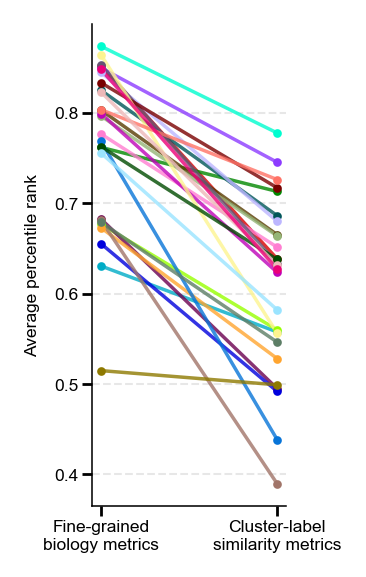

In [185]:
data = []
for i, row in df_pivot.iterrows():
    data.append((i, row['True_1'], row['True_2']))

palette = cc.glasbey
with plt.rc_context({'figure.dpi': 250}):
    fig, ax = plt.subplots(figsize=(1, 2.5))

    for i, (name, x_val, y_val) in enumerate(data):
        color = palette[i % len(palette)]

        ax.plot([0, 1], [x_val, y_val], color=color, linewidth=1, markersize=1, alpha=0.8, label=name)
        ax.scatter([0, 1], [x_val, y_val], color=color, s=1, zorder=3)
    ax.tick_params(axis='x', labelsize=12)
    ax.tick_params(axis='y', labelsize=12)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Fine-grained\nbiology metrics', 'Cluster-label\nsimilarity metrics'], fontsize=5, fontweight='bold')
    ax.set_ylabel("Average percentile rank", fontsize=5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='major', width=.8, length=3, labelsize=5, pad=1)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)
    ax.yaxis.grid(True, linestyle='--', alpha=0.3, linewidth=.6)

    plt.tight_layout()
    plt.savefig('../publication_figures/pca_based_cluster_label.png', dpi=250, bbox_inches='tight')
    plt.show()

In [17]:
pca_based = ['harmony-1', 'scanorama-1', 'rpca-1', 'mnn-1']
celltypes_cluster = ['casw', 'cdbi','cch']
df['Rank'] = df.groupby(['Dataset', 'Metric'])['Value'].rank(ascending=True, method='min', pct=True)

df['is_pca_based'] = df['Integration'].isin(pca_based)
df['is_target_metric'] = df['Metric'].isin(['scgraph'])

sub_df1 = df[df['Metric'].isin(['corrmse', 'agree', 'traj', 'morani', 'rknn', 'ccc', 'scgraph', 'ldfdiff'])]
sub_df2 = df[~df['Metric'].isin(celltypes_cluster)]

In [18]:
sub_df1_agg = sub_df1.groupby(['Dataset', 'is_pca_based'])['Rank'].mean().reset_index()
df_pivot1 = sub_df1_agg.pivot(index='Dataset', columns='is_pca_based', values='Rank')
df_pivot1['Difference'] = df_pivot1[False] - df_pivot1[True]

sub_df2_agg = sub_df2.groupby(['Dataset', 'is_pca_based'])['Rank'].mean().reset_index()
df_pivot2 = sub_df2_agg.pivot(index='Dataset', columns='is_pca_based', values='Rank')
df_pivot2['Difference'] = df_pivot2[False] - df_pivot2[True]

In [19]:
stat, p_value = scipy.stats.wilcoxon(df_pivot1[True], df_pivot2[True], alternative='greater')
stat, p_value

(np.float64(378.0), np.float64(7.450580596923828e-09))

In [20]:
stat, p_value = scipy.stats.wilcoxon(df_pivot1['Difference'], df_pivot2['Difference'], alternative='less')
stat, p_value

(np.float64(0.0), np.float64(7.450580596923828e-09))

In [21]:
df_pivot = df_pivot1.join(df_pivot2, lsuffix='_1', rsuffix='_2')

/tmp/ipykernel_2962959/1397520152.py:38: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


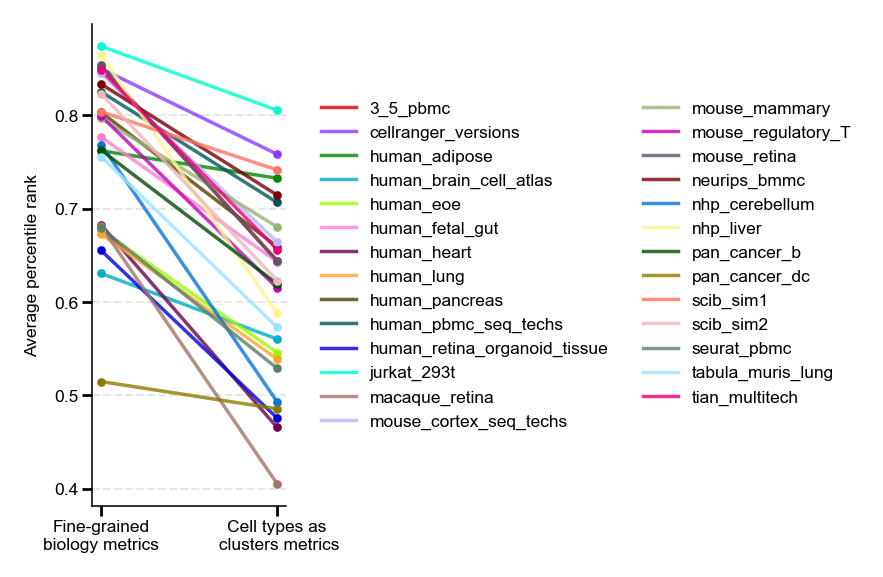

In [23]:
data = []
for i, row in df_pivot.iterrows():
    data.append((i, row['True_1'], row['True_2']))

palette = cc.glasbey
with plt.rc_context({'figure.dpi': 250}):
    fig, ax = plt.subplots(figsize=(1, 2.5))

    for i, (name, x_val, y_val) in enumerate(data):
        color = palette[i % len(palette)]

        ax.plot([0, 1], [x_val, y_val], color=color, linewidth=1, markersize=1, alpha=0.8, label=name)
        ax.scatter([0, 1], [x_val, y_val], color=color, s=1, zorder=3)
    ax.tick_params(axis='x', labelsize=12)
    ax.tick_params(axis='y', labelsize=12)
    ax.legend(loc='center left', bbox_to_anchor=(1.1, 0.5), title="", frameon=False, ncol=2, fontsize=5)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Fine-grained\nbiology metrics', 'Cell types as\n clusters metrics'], fontsize=5, fontweight='bold')
    ax.set_ylabel("Average percentile rank", fontsize=5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='major', width=.8, length=3, labelsize=5, pad=1)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)
    ax.yaxis.grid(True, linestyle='--', alpha=0.3, linewidth=.6)

    plt.tight_layout()
    plt.savefig('../publication_figures/pca_based_celltype_cluster.png', dpi=250, bbox_inches='tight')
    plt.show()

In [102]:
# Alternatively through linear regression

m = 'scgraph'
sub = df[df['Metric'].isin(['bari', 'clisi', 'casw', m])][['Metric', 'is_pca_based', 'Value', 'Dataset', 'Integration']]
sub = sub.groupby(['Dataset', 'Integration']).filter(
    lambda x: x['Value'].notna().sum() == 4
)
sub = sub.pivot(
    index=['Dataset', 'is_pca_based', 'Integration'], 
    columns='Metric', 
    values='Value'
).reset_index()

X = sub[['is_pca_based',  'bari', 'casw', 'clisi']].astype(float)
X = sm.add_constant(X) # Adds the intercept term
y = sub[m]

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                scgraph   R-squared:                       0.149
Model:                            OLS   Adj. R-squared:                  0.144
Method:                 Least Squares   F-statistic:                     31.17
Date:                Wed, 29 Apr 2026   Prob (F-statistic):           6.17e-24
Time:                        10:44:35   Log-Likelihood:                 243.06
No. Observations:                 716   AIC:                            -476.1
Df Residuals:                     711   BIC:                            -453.3
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.6902      0.092      7.497   

In [103]:
# Alternatively through linear regression

m = 'rknn'
sub = df[df['Metric'].isin(['bari', 'clisi', 'casw', m])][['Metric', 'is_pca_based', 'Value', 'Dataset', 'Integration']]
sub = sub.groupby(['Dataset', 'Integration']).filter(
    lambda x: x['Value'].notna().sum() == 4
)
sub = sub.pivot(
    index=['Dataset', 'is_pca_based', 'Integration'], 
    columns='Metric', 
    values='Value'
).reset_index()

X = sub[['is_pca_based','bari', 'casw', 'clisi']].astype(float)
X = sm.add_constant(X) # Adds the intercept term
y = sub[m]

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   rknn   R-squared:                       0.165
Model:                            OLS   Adj. R-squared:                  0.161
Method:                 Least Squares   F-statistic:                     36.83
Date:                Wed, 29 Apr 2026   Prob (F-statistic):           4.05e-28
Time:                        10:53:00   Log-Likelihood:                 550.67
No. Observations:                 749   AIC:                            -1091.
Df Residuals:                     744   BIC:                            -1068.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0433      0.052      0.834   

In [104]:
# Alternatively through linear regression

m = 'agree'
sub = df[df['Metric'].isin(['bari', 'clisi', 'casw', m])][['Metric', 'is_pca_based', 'Value', 'Dataset', 'Integration']]
sub = sub.groupby(['Dataset', 'Integration']).filter(
    lambda x: x['Value'].notna().sum() == 4
)
sub = sub.pivot(
    index=['Dataset', 'is_pca_based', 'Integration'], 
    columns='Metric', 
    values='Value'
).reset_index()

X = sub[['is_pca_based', 'bari', 'casw', 'clisi']].astype(float)
X = sm.add_constant(X) # Adds the intercept term
y = sub[m]

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  agree   R-squared:                       0.166
Model:                            OLS   Adj. R-squared:                  0.161
Method:                 Least Squares   F-statistic:                     36.95
Date:                Wed, 29 Apr 2026   Prob (F-statistic):           3.37e-28
Time:                        10:55:02   Log-Likelihood:                 787.82
No. Observations:                 748   AIC:                            -1566.
Df Residuals:                     743   BIC:                            -1543.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.0014      0.038     -0.038   

In [105]:
# Alternatively through linear regression

m = 'morani'
sub = df[df['Metric'].isin(['bari', 'clisi', 'casw', m])][['Metric', 'is_pca_based', 'Value', 'Dataset', 'Integration']]
sub = sub.groupby(['Dataset', 'Integration']).filter(
    lambda x: x['Value'].notna().sum() == 4
)
sub = sub.pivot(
    index=['Dataset', 'is_pca_based', 'Integration'], 
    columns='Metric', 
    values='Value'
).reset_index()

X = sub[['is_pca_based', 'bari', 'casw', 'clisi']].astype(float)
X = sm.add_constant(X) # Adds the intercept term
y = sub[m]

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 morani   R-squared:                       0.061
Model:                            OLS   Adj. R-squared:                  0.055
Method:                 Least Squares   F-statistic:                     11.03
Date:                Wed, 29 Apr 2026   Prob (F-statistic):           1.13e-08
Time:                        10:55:21   Log-Likelihood:                -8.3451
No. Observations:                 687   AIC:                             26.69
Df Residuals:                     682   BIC:                             49.35
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.7082      0.115      6.165   

In [106]:
# Alternatively through linear regression

m = 'traj'
sub = df[df['Metric'].isin(['bari', 'clisi', 'casw', m])][['Metric', 'is_pca_based', 'Value', 'Dataset', 'Integration']]
sub = sub.groupby(['Dataset', 'Integration']).filter(
    lambda x: x['Value'].notna().sum() == 4
)
sub = sub.pivot(
    index=['Dataset', 'is_pca_based', 'Integration'], 
    columns='Metric', 
    values='Value'
).reset_index()

X = sub[['is_pca_based', 'bari', 'casw', 'clisi']].astype(float)
X = sm.add_constant(X) # Adds the intercept term
y = sub[m]

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   traj   R-squared:                       0.250
Model:                            OLS   Adj. R-squared:                  0.214
Method:                 Least Squares   F-statistic:                     6.913
Date:                Wed, 29 Apr 2026   Prob (F-statistic):           7.47e-05
Time:                        10:55:30   Log-Likelihood:                 49.493
No. Observations:                  88   AIC:                            -88.99
Df Residuals:                      83   BIC:                            -76.60
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -1.3868      0.888     -1.561   

In [107]:
# Alternatively through linear regression

m = 'corrmse'
sub = df[df['Metric'].isin(['bari', 'clisi', 'casw', m])][['Metric', 'is_pca_based', 'Value', 'Dataset', 'Integration']]
sub = sub.groupby(['Dataset', 'Integration']).filter(
    lambda x: x['Value'].notna().sum() == 4
)
sub = sub.pivot(
    index=['Dataset', 'is_pca_based', 'Integration'], 
    columns='Metric', 
    values='Value'
).reset_index()

X = sub[['is_pca_based', 'bari', 'casw', 'clisi']].astype(float)
X = sm.add_constant(X) # Adds the intercept term
y = sub[m]

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                corrmse   R-squared:                       0.169
Model:                            OLS   Adj. R-squared:                  0.164
Method:                 Least Squares   F-statistic:                     34.77
Date:                Wed, 29 Apr 2026   Prob (F-statistic):           1.88e-26
Time:                        10:55:40   Log-Likelihood:                 134.55
No. Observations:                 691   AIC:                            -259.1
Df Residuals:                     686   BIC:                            -236.4
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.3657      0.090      4.045   

In [108]:
# Alternatively through linear regression

m = 'ccc'
sub = df[df['Metric'].isin(['bari', 'clisi', 'casw', m])][['Metric', 'is_pca_based', 'Value', 'Dataset', 'Integration']]
sub = sub.groupby(['Dataset', 'Integration']).filter(
    lambda x: x['Value'].notna().sum() == 4
)
sub = sub.pivot(
    index=['Dataset', 'is_pca_based', 'Integration'], 
    columns='Metric', 
    values='Value'
).reset_index()

X = sub[['is_pca_based', 'bari', 'casw', 'clisi']].astype(float)
X = sm.add_constant(X) # Adds the intercept term
y = sub[m]

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    ccc   R-squared:                       0.072
Model:                            OLS   Adj. R-squared:                  0.066
Method:                 Least Squares   F-statistic:                     11.30
Date:                Wed, 29 Apr 2026   Prob (F-statistic):           7.77e-09
Time:                        10:55:45   Log-Likelihood:                 115.49
No. Observations:                 584   AIC:                            -221.0
Df Residuals:                     579   BIC:                            -199.1
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.3721      0.096      3.870   

In [112]:
# Alternatively through linear regression

m = 'ldfdiff'
sub = df[df['Metric'].isin(['bari', 'clisi', 'casw', m])][['Metric', 'is_pca_based', 'Value', 'Dataset', 'Integration']]
sub = sub.groupby(['Dataset', 'Integration']).filter(
    lambda x: x['Value'].notna().sum() == 4
)
sub = sub.pivot(
    index=['Dataset', 'is_pca_based', 'Integration'], 
    columns='Metric', 
    values='Value'
).reset_index()

X = sub[['is_pca_based', 'bari', 'casw', 'clisi']].astype(float)
X = sm.add_constant(X) # Adds the intercept term
y = sub[m]

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                ldfdiff   R-squared:                       0.121
Model:                            OLS   Adj. R-squared:                  0.116
Method:                 Least Squares   F-statistic:                     25.12
Date:                Wed, 29 Apr 2026   Prob (F-statistic):           1.64e-19
Time:                        10:56:31   Log-Likelihood:                 168.64
No. Observations:                 733   AIC:                            -327.3
Df Residuals:                     728   BIC:                            -304.3
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.7774      0.086      8.996   

In [138]:
# Alternatively through linear regression

m = 'gc'
sub = df[df['Metric'].isin(['bari', 'clisi', 'casw', m])][['Metric', 'is_pca_based', 'Value', 'Dataset', 'Integration']]
sub = sub.groupby(['Dataset', 'Integration']).filter(
    lambda x: x['Value'].notna().sum() == 4
)
sub = sub.pivot(
    index=['Dataset', 'is_pca_based', 'Integration'], 
    columns='Metric', 
    values='Value'
).reset_index()

X = sub[['is_pca_based', 'bari', 'casw', 'clisi']].astype(float)
X = sm.add_constant(X) # Adds the intercept term
y = sub[m]

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                     gc   R-squared:                       0.412
Model:                            OLS   Adj. R-squared:                  0.409
Method:                 Least Squares   F-statistic:                     130.4
Date:                Wed, 29 Apr 2026   Prob (F-statistic):           2.40e-84
Time:                        11:33:59   Log-Likelihood:                 637.63
No. Observations:                 749   AIC:                            -1265.
Df Residuals:                     744   BIC:                            -1242.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.8997      0.046     19.457   

In [168]:
# Alternatively through linear regression

m = 'scgraph'
sub = df[df['Metric'].isin(['bari', 'clisi', 'casw', m])][['Metric', 'is_pca_based', 'Value', 'Dataset', 'Integration']]
sub = sub.groupby(['Dataset', 'Integration']).filter(
    lambda x: x['Value'].notna().sum() == 4
)
sub = sub.pivot(
    index=['Dataset', 'is_pca_based', 'Integration'], 
    columns='Metric', 
    values='Value'
).reset_index()

X = sub[['is_pca_based',  'bari', 'clisi', 'casw']].astype(float)
X = sm.add_constant(X) # Adds the intercept term
y = sub[m]

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                scgraph   R-squared:                       0.149
Model:                            OLS   Adj. R-squared:                  0.144
Method:                 Least Squares   F-statistic:                     31.17
Date:                Mon, 27 Apr 2026   Prob (F-statistic):           6.17e-24
Time:                        12:42:29   Log-Likelihood:                 243.06
No. Observations:                 716   AIC:                            -476.1
Df Residuals:                     711   BIC:                            -453.3
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.6902      0.092      7.497   

## Difference between PCA and Fisher-Rao distance for scGraph

In [62]:
pca_based = ['harmony-1', 'scanorama-1', 'rpca-1', 'mnn-1', 'pca-1']

In [63]:
df2 = df_full[df_full["Metric"].isin(['scgraphp', 'scgraphm', 'scgraph'])]

In [64]:
df2 = df2.groupby(['Dataset', 'Integration']).filter(
    lambda x: x['Value'].notna().sum() == 3
)

In [65]:
df2['Rank'] = df2.groupby(['Metric', 'Dataset'])['Value'].rank(
    ascending=True,
    method='min', pct=True
)

In [66]:
df2['is_pca_based'] = df2['Integration'].isin(pca_based)
df2['Integration'] = df2['Integration'].str[:-2].replace(NAME_MAP)

In [67]:
pivot_df = df2.pivot_table(
    index=['Dataset', 'Integration'], 
    columns='Metric', 
    values='Rank'
)

In [68]:
means = pivot_df.groupby('Integration')[['scgraph', 'scgraphm', 'scgraphp']].mean()

In [69]:
means['m_diff'] = means['scgraphm'] - means['scgraph']
means['p_diff'] = means['scgraphp'] - means['scgraph']

In [70]:
sns.color_palette()[0]


(0.12156862745098039, 0.4666666666666667, 0.7058823529411765)

/tmp/ipykernel_2962959/3569093687.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


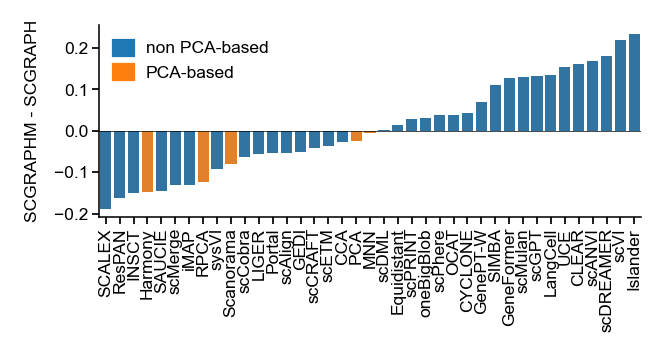

In [72]:
import matplotlib.patches as mpatches

with plt.rc_context({'figure.dpi': 250}):
    fig, ax = plt.subplots(figsize=(2.8, 1))
    
    sorted_df = means.sort_values('m_diff').reset_index()
    colors = [sns.color_palette()[1] if x in ['PCA', 'MNN', 'RPCA', 'Scanorama', 'Harmony'] else sns.color_palette()[0] 
              for x in sorted_df['Integration']]
    sns.barplot(
        sorted_df,
        x='Integration', y='m_diff',
        palette=colors,ax=ax
    )
    
    legend_handles = [
        mpatches.Patch(color=sns.color_palette()[0] , label='non PCA-based'),
        mpatches.Patch(color=sns.color_palette()[1], label='PCA-based'),
    ]
    ax.legend(handles=legend_handles, fontsize=5, frameon=False,
              loc='upper left', handlelength=1, handleheight=0.8)
    ax.set_ylabel('SCGRAPHM - SCGRAPH', fontsize=5)
    ax.set_xlabel('')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.axhline(y=0, color='black', linewidth=0.2)
    ax.tick_params(axis='both', which='major', width=.5, length=2, labelsize=5, pad=1)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)
    plt.xticks(rotation=90)
    plt.savefig('../publication_figures/scgraphm_diff.png', dpi=250, bbox_inches='tight')
    plt.show()

/tmp/ipykernel_2962959/1920419248.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


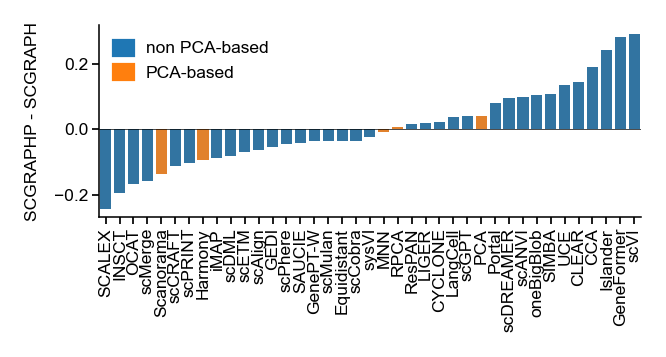

In [73]:
import matplotlib.patches as mpatches

with plt.rc_context({'figure.dpi': 250}):
    fig, ax = plt.subplots(figsize=(2.8, 1))
    
    sorted_df = means.sort_values('p_diff').reset_index()
    colors = [sns.color_palette()[1] if x in ['PCA', 'MNN', 'RPCA', 'Scanorama', 'Harmony'] else sns.color_palette()[0] 
              for x in sorted_df['Integration']]
    sns.barplot(
        sorted_df,
        x='Integration', y='p_diff',
        palette=colors,ax=ax
    )
    
    legend_handles = [
        mpatches.Patch(color=sns.color_palette()[0] , label='non PCA-based'),
        mpatches.Patch(color=sns.color_palette()[1], label='PCA-based'),
    ]
    ax.legend(handles=legend_handles, fontsize=5, frameon=False,
              loc='upper left', handlelength=1, handleheight=0.8)
    ax.set_ylabel('SCGRAPHP - SCGRAPH', fontsize=5)
    ax.set_xlabel('')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.axhline(y=0, color='black', linewidth=0.2)
    ax.tick_params(axis='both', which='major', width=.5, length=2, labelsize=5, pad=1)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)
    plt.xticks(rotation=90)
    plt.savefig('../publication_figures/scgraphp_diff.png', dpi=250, bbox_inches='tight')
    plt.show()

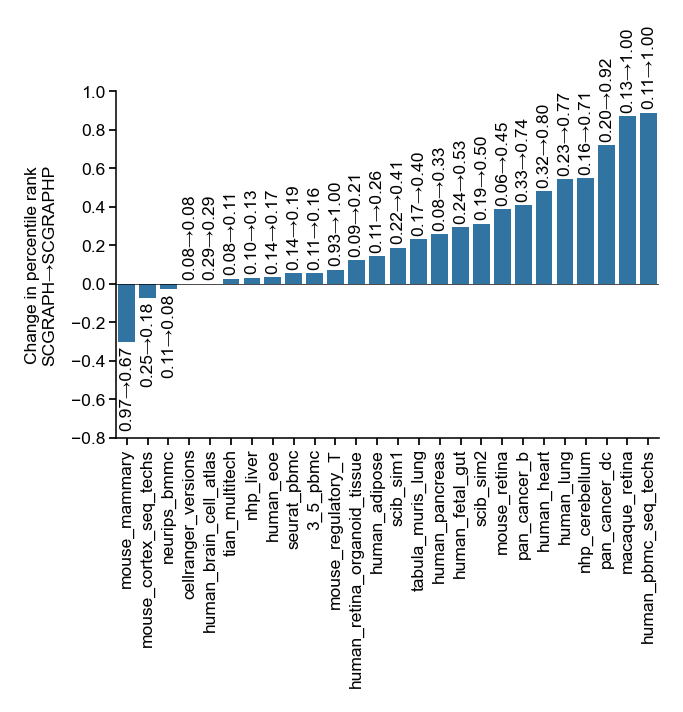

In [33]:
df3 = df2[df2['Integration'] == 'islander-1'].pivot_table(
    index=['Dataset'],
    columns='Metric',
    values='Rank'
)
df3['diff'] = df3['scgraphp'] - df3['scgraph']
sorted_df = df3.sort_values('diff').reset_index()

with plt.rc_context({'figure.dpi': 250}):
    fig, ax = plt.subplots(figsize=(2.8, 1.8))
    sns.barplot(
        sorted_df,
        x='Dataset', y='diff',
        ax=ax
    )
    
    for i, (_, row) in enumerate(sorted_df.iterrows()):
        bar_top = row['diff']
        label = f"{row['scgraph']:.2f}→{row['scgraphp']:.2f}"
        
        va = 'bottom' if bar_top >= 0 else 'top'
        offset = 0.02 if bar_top >= 0 else -0.02
        
        ax.text(i, bar_top + offset, label, ha='center', va=va,
                fontsize=5, rotation=90, color='black')

    ax.set_ylabel('Change in percentile rank\nSCGRAPH→SCGRAPHP', fontsize=5)
    ax.set_xlabel('')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.axhline(y=0, color='black', linewidth=0.2)
    ax.tick_params(axis='both', which='major', width=.5, length=2, labelsize=5, pad=1)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)
    plt.xticks(rotation=90)
    plt.ylim(-.8, 1)
    plt.savefig('../publication_figures/scgraphp_islander_diff.png', dpi=250, bbox_inches='tight')
    plt.show()

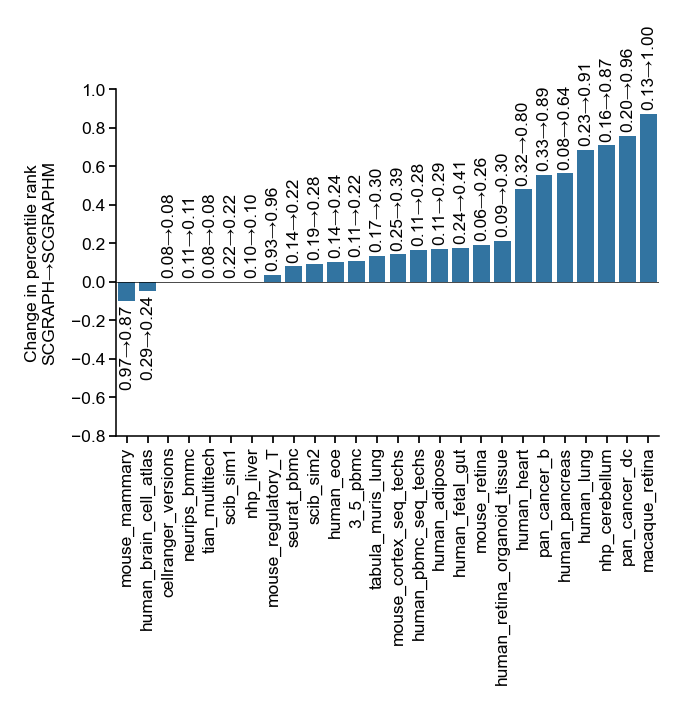

In [35]:
df3 = df2[df2['Integration'] == 'islander-1'].pivot_table(
    index=['Dataset'],
    columns='Metric',
    values='Rank'
)
df3['diff'] = df3['scgraphm'] - df3['scgraph']
sorted_df = df3.sort_values('diff').reset_index()

with plt.rc_context({'figure.dpi': 250}):
    fig, ax = plt.subplots(figsize=(2.8, 1.8))
    sns.barplot(
        sorted_df,
        x='Dataset', y='diff',
        ax=ax
    )
    
    for i, (_, row) in enumerate(sorted_df.iterrows()):
        bar_top = row['diff']
        label = f"{row['scgraph']:.2f}→{row['scgraphm']:.2f}"
        
        # Place annotation above or below bar depending on sign
        va = 'bottom' if bar_top >= 0 else 'top'
        offset = 0.02 if bar_top >= 0 else -0.02
        
        ax.text(i, bar_top + offset, label, ha='center', va=va,
                fontsize=5, rotation=90, color='black')

    ax.set_ylabel('Change in percentile rank\nSCGRAPH→SCGRAPHM', fontsize=5)
    ax.set_xlabel('')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.axhline(y=0, color='black', linewidth=0.2)
    ax.tick_params(axis='both', which='major', width=.5, length=2, labelsize=5, pad=1)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)
    plt.xticks(rotation=90)
    plt.ylim(-.8, 1)
    plt.savefig('../publication_figures/scgraphm_islander_diff.png', dpi=250, bbox_inches='tight')
    plt.show()

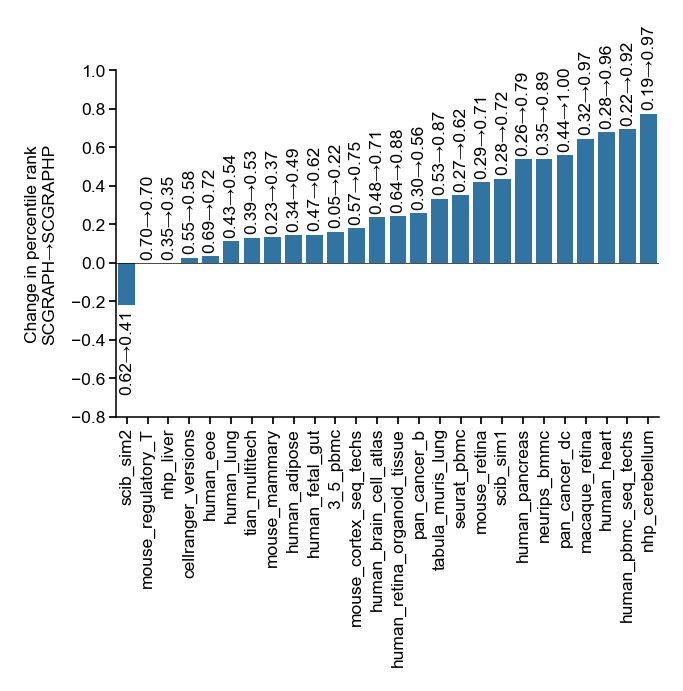

In [36]:
df3 = df2[df2['Integration'] == 'scvi-1'].pivot_table(
    index=['Dataset'],
    columns='Metric',
    values='Rank'
)
df3['diff'] = df3['scgraphp'] - df3['scgraph']
sorted_df = df3.sort_values('diff').reset_index()

with plt.rc_context({'figure.dpi': 250}):
    fig, ax = plt.subplots(figsize=(2.8, 1.8))
    sns.barplot(
        sorted_df,
        x='Dataset', y='diff',
        ax=ax
    )
    
    for i, (_, row) in enumerate(sorted_df.iterrows()):
        bar_top = row['diff']
        label = f"{row['scgraph']:.2f}→{row['scgraphp']:.2f}"
        
        # Place annotation above or below bar depending on sign
        va = 'bottom' if bar_top >= 0 else 'top'
        offset = 0.02 if bar_top >= 0 else -0.02
        
        ax.text(i, bar_top + offset, label, ha='center', va=va,
                fontsize=5, rotation=90, color='black')

    ax.set_ylabel('Change in percentile rank\nSCGRAPH→SCGRAPHP', fontsize=5)
    ax.set_xlabel('')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.axhline(y=0, color='black', linewidth=0.2)
    ax.tick_params(axis='both', which='major', width=.5, length=2, labelsize=5, pad=1)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)
    plt.xticks(rotation=90)
    plt.ylim(-.8, 1)
    plt.savefig('../publication_figures/scgraphp_scvi_diff.png', dpi=250, bbox_inches='tight')
    plt.show()

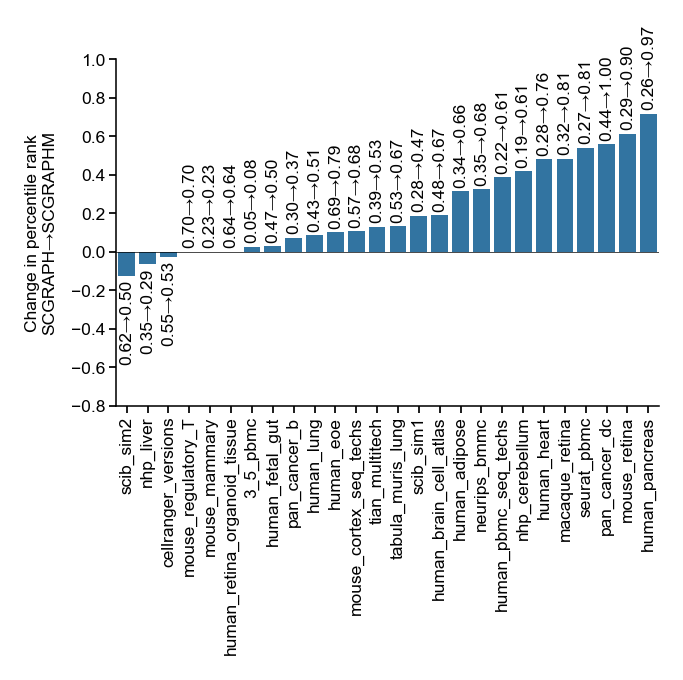

In [37]:
df3 = df2[df2['Integration'] == 'scvi-1'].pivot_table(
    index=['Dataset'],
    columns='Metric',
    values='Rank'
)
df3['diff'] = df3['scgraphm'] - df3['scgraph']
sorted_df = df3.sort_values('diff').reset_index()

with plt.rc_context({'figure.dpi': 250}):
    fig, ax = plt.subplots(figsize=(2.8, 1.8))
    sns.barplot(
        sorted_df,
        x='Dataset', y='diff',
        ax=ax
    )
    
    for i, (_, row) in enumerate(sorted_df.iterrows()):
        bar_top = row['diff']
        label = f"{row['scgraph']:.2f}→{row['scgraphm']:.2f}"
        
        # Place annotation above or below bar depending on sign
        va = 'bottom' if bar_top >= 0 else 'top'
        offset = 0.02 if bar_top >= 0 else -0.02
        
        ax.text(i, bar_top + offset, label, ha='center', va=va,
                fontsize=5, rotation=90, color='black')

    ax.set_ylabel('Change in percentile rank\nSCGRAPH→SCGRAPHM', fontsize=5)
    ax.set_xlabel('')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.axhline(y=0, color='black', linewidth=0.2)
    ax.tick_params(axis='both', which='major', width=.5, length=2, labelsize=5, pad=1)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)
    plt.xticks(rotation=90)
    plt.ylim(-.8, 1)
    plt.savefig('../publication_figures/scgraphm_scvi_diff.png', dpi=250, bbox_inches='tight')
    plt.show()

## Compute Fisher-Rao distance on specific datasets

In [327]:
dataset = 'nph_cerebellum'

In [328]:
adata = sc.read(f'../data/{dataset}.h5ad')

In [329]:
d = runs[runs.name.str.contains(dataset) & runs.name.str.contains('scvi')].iloc[0]['workdir']
adata_int = sc.read(f"{d}/save_dir/adata.h5ad")
batch_col = dataset_keys[dataset]['batch_keys'][0]
celltype_col = dataset_keys[dataset]['celltype_keys'][0]

if adata_int.X is None:
    adata_int = ad.AnnData(
        X=adata.X,
        obs=adata_int.obs,
        var=adata.var,
        uns=adata_int.uns,
        obsm=adata_int.obsm,
        varm=adata_int.varm,
        obsp=adata_int.obsp,
        varp=adata.varp,
        layers=adata.layers,
)

adata_int

AnnData object with n_obs × n_vars = 84619 × 18892
    obs: 'Sample', 'Celltype', 'cluster_0.2', 'cluster_0.4', 'cluster_0.6', 'cluster_0.8', 'cluster_1.0', 'cluster_1.2', 'cluster_1.4', 'cluster_1.6', 'cluster_1.8', 'cluster_2.0'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'seurat_v3_highly_variable', 'dispersions', 'dispersions_norm'
    uns: 'cluster_0.2', 'cluster_0.4', 'cluster_0.6', 'cluster_0.8', 'cluster_1.0', 'cluster_1.2', 'cluster_1.4', 'cluster_1.6', 'cluster_1.8', 'cluster_2.0', 'neighbors'
    obsm: 'X_integration', 'X_umap'
    layers: 'counts', 'orig_counts'
    obsp: 'connectivities', 'distances'

In [298]:
adata_int.obs['CellType'] = adata_int.obs['CellType'].replace('Plasmacytoid dendritic cell', 'pDC')

/tmp/ipykernel_3425353/2105310240.py:1: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  adata_int.obs['CellType'] = adata_int.obs['CellType'].replace('Plasmacytoid dendritic cell', 'pDC')


In [126]:
def fisher_poisson(m1, m2):
    return np.sum( 2 * np.abs(np.sqrt(m1) - np.sqrt(m2)) )

def fisher_multinomial(m1, m2):
    v = np.sum(np.sqrt(m1 * m2))
    v = np.clip(v, -1, 1)
    return 2 * np.arccos(v)

In [21]:
means = []
for ct in adata.obs['cell_type'].unique():
    sub = adata[adata.obs['cell_type'] == ct]
    means.append(sub.layers['counts'].mean(0).A1)
means = np.array(means)

In [26]:
poisson_dists = sklearn.metrics.pairwise_distances(means, metric=fisher_poisson)

array([[   0.        , 3342.29199219, 6485.84570312, ..., 2862.671875  ,
        5156.24414062, 6399.57324219],
       [3342.29199219,    0.        , 6850.82324219, ..., 4041.54882812,
        5134.71923828, 6785.55957031],
       [6485.84570312, 6850.82324219,    0.        , ..., 7053.99658203,
        6715.89501953, 6103.19091797],
       ...,
       [2862.671875  , 4041.54882812, 7053.99658203, ...,    0.        ,
        5158.57910156, 5792.00292969],
       [5156.24414062, 5134.71923828, 6715.89501953, ..., 5158.57910156,
           0.        , 5893.85986328],
       [6399.57324219, 6785.55957031, 6103.19091797, ..., 5792.00292969,
        5893.85986328,    0.        ]], shape=(45, 45))

In [27]:
props = []
for ct in adata.obs['cell_type'].unique():
    sub = adata[adata.obs['cell_type'] == ct]
    sums = sub.layers['counts'].sum(0).A1
    prop = sums / np.sum(sums)
    props.append(prop)
props = np.array(props)

In [40]:
multinomial_dists = sklearn.metrics.pairwise_distances(props, metric=fisher_multinomial)

In [42]:
pd.DataFrame(multinomial_dists, index=adata.obs['cell_type'].unique(), columns=adata.obs['cell_type'].unique())

,Naive CD20+ B IGKC+,CD14+ Mono,HSC,Reticulocyte,Normoblast,NK CD158e1+,CD4+ T naive,Erythroblast,NK,B1 B IGKC-,...,Plasma cell IGKC+,Plasma cell IGKC-,CD4+ T CD314+ CD45RA+,ILC,CD8+ T naive CD127+ CD26- CD101-,gdT CD158b+,CD8+ T CD57+ CD45RO+,dnT,cDC1,T prog cycling
Naive CD20+ B IGKC+,0.000000,1.077157,0.708913,2.722074,2.474615,0.876342,0.620243,1.796908,0.828141,0.332458,...,1.461190,1.409772,0.796555,1.094835,0.695256,0.793533,0.810561,0.666372,0.907971,1.013599
CD14+ Mono,1.077157,0.000000,1.087570,2.725104,2.492522,1.038410,1.138223,1.901320,1.017477,1.036687,...,1.757467,1.672765,1.041029,1.212639,1.087898,1.035593,1.051204,1.083368,1.005376,1.116674
HSC,0.708913,1.087570,0.000977,2.763478,2.529956,0.975488,0.636868,1.757735,0.917249,0.679399,...,1.643559,1.568907,0.920602,1.281021,0.768057,0.893295,0.927935,0.761865,0.891854,0.944469
Reticulocyte,2.722074,2.725104,2.763478,0.000977,0.470306,2.727886,2.741168,1.244329,2.737272,2.748929,...,2.779742,2.821220,2.752983,2.736862,2.759871,2.730604,2.756490,2.709795,2.807337,2.785213
Normoblast,2.474615,2.492522,2.529956,0.470306,0.000000,2.467763,2.499678,0.963062,2.479448,2.504052,...,2.602224,2.632007,2.497076,2.461321,2.514041,2.472797,2.494248,2.463809,2.588625,2.557745
NK CD158e1+,0.876342,1.038410,0.975488,2.727886,2.467763,0.000000,0.839549,1.847548,0.137596,0.841968,...,1.677328,1.577028,0.478360,0.677189,0.705905,0.282817,0.370724,0.698524,1.083660,0.899896
CD4+ T naive,0.620243,1.138223,0.636868,2.741168,2.499678,0.839549,0.000000,1.800840,0.784603,0.580642,...,1.654557,1.581475,0.665261,1.137692,0.434670,0.704194,0.708622,0.433436,0.986889,0.965107
Erythroblast,1.796908,1.901320,1.757735,1.244329,0.963062,1.847548,1.800840,0.000000,1.843869,1.820183,...,2.132658,2.142862,1.867151,1.946994,1.845219,1.835460,1.861959,1.795235,1.926388,1.821727
NK,0.828141,1.017477,0.917249,2.737272,2.479448,0.137596,0.784603,1.843869,0.000000,0.802384,...,1.668068,1.587082,0.442980,0.692483,0.646487,0.240825,0.352700,0.642998,1.043944,0.865246
B1 B IGKC-,0.332458,1.036687,0.679399,2.748929,2.504052,0.841968,0.580642,1.820183,0.802384,0.000000,...,1.540641,1.406709,0.739328,1.106854,0.646822,0.748830,0.758464,0.622134,0.839382,0.953827


In [330]:
sg = scGraph(adata_int, batch_col, celltype_col, 'default')
sg.preprocess()
sg.process_batches()
sg.calculate_consensus()

Processing batches, calculate centroids and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:09<00:00,  4.63s/it]


In [331]:
sg1 = scGraph(adata_int, batch_col, celltype_col, 'fisher_poisson')
sg1.preprocess()
sg1.process_batches_fisher()
sg1.calculate_consensus()

Processing batches using Fisher information metric and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:03<00:00,  1.61s/it]


In [332]:
sg2 = scGraph(adata_int, batch_col, celltype_col, 'fisher_multinomial')
sg2.preprocess()
sg2.process_batches_fisher()
sg2.calculate_consensus()

Processing batches using Fisher information metric and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:07<00:00,  3.57s/it]


In [333]:
sg.consensus_df

,Astrocyte,Granule cell,Microglia,Molecular interneuron,OPC,Oligodendrocyte,Purkinje,Stromal cell
Astrocyte,0.000000,1.000000,1.000000,0.998740,0.901635,0.989039,0.959816,0.942537
Granule cell,0.876693,0.000000,0.382617,0.701682,0.918456,0.836542,0.511418,0.543922
Microglia,0.822629,0.358714,0.000000,0.670508,0.847645,0.692190,0.485046,0.313605
Molecular interneuron,1.000000,0.801605,0.816214,0.000000,0.924001,1.000000,0.437983,0.904368
OPC,0.793944,0.922438,0.907113,0.812911,0.000000,0.880248,0.809149,0.960436
Oligodendrocyte,0.990475,0.957409,0.845282,1.000000,1.000000,0.000000,1.000000,1.000000
Purkinje,0.811776,0.495124,0.501031,0.368441,0.775703,0.846319,0.000000,0.611398
Stromal cell,0.765972,0.505839,0.310477,0.734046,0.885787,0.808162,0.592576,0.000000


In [334]:
sg1.consensus_df

,Astrocyte,Granule cell,Microglia,Molecular interneuron,OPC,Oligodendrocyte,Purkinje,Stromal cell
Astrocyte,0.000000,0.948334,0.940491,0.957017,0.811783,0.856319,0.982285,0.777644
Granule cell,0.803432,0.000000,0.678102,0.690349,0.866909,0.711723,0.675726,0.834250
Microglia,0.828324,0.706911,0.000000,0.876898,0.905135,0.779504,0.853353,0.703153
Molecular interneuron,0.962578,0.816729,1.000000,0.000000,0.911739,1.000000,0.707083,0.986356
OPC,0.748767,0.942796,0.948506,0.837410,0.000000,0.858449,0.903283,0.883158
Oligodendrocyte,0.822060,0.813718,0.849735,0.958657,0.894489,0.000000,0.914820,0.891701
Purkinje,1.000000,0.823349,0.986515,0.723263,1.000000,0.969830,0.000000,1.000000
Stromal cell,0.799923,1.000000,0.815999,1.000000,0.978230,0.949746,1.000000,0.000000


In [335]:
sg2.consensus_df

,Astrocyte,Granule cell,Microglia,Molecular interneuron,OPC,Oligodendrocyte,Purkinje,Stromal cell
Astrocyte,0.000000,0.996955,0.911197,0.955733,0.799032,0.851186,0.960326,0.807108
Granule cell,0.902853,0.000000,0.806264,0.752758,0.904593,0.867425,0.850743,0.899322
Microglia,0.869768,0.852171,0.000000,0.900942,0.901650,0.812520,0.917651,0.758564
Molecular interneuron,0.910037,0.791078,0.897438,0.000000,0.805895,0.913104,0.724218,0.924728
OPC,0.752500,0.940797,0.889239,0.797405,0.000000,0.825718,0.903131,0.891060
Oligodendrocyte,0.885676,1.000000,0.885449,1.000000,0.913253,0.000000,1.000000,0.934343
Purkinje,1.000000,0.982486,1.000000,0.795520,1.000000,1.000000,0.000000,1.000000
Stromal cell,0.803134,0.983533,0.786010,0.961776,0.937917,0.890722,0.950892,0.000000


In [253]:
sg.consensus_df

,B cell,CD14+ monocyte,CD16+ monocyte,CD4+ T cell,Cytotoxic T cell,Megakaryocyte,Natural killer cell,Dendritic cell,Plasmacytoid dendritic cell
B cell,0.000000,0.588830,0.552238,0.402603,0.459491,0.983380,0.536640,0.438124,0.263206
CD14+ monocyte,0.602231,0.000000,0.392842,0.608510,0.633249,1.000000,0.687881,0.315686,0.549531
CD16+ monocyte,0.541701,0.373924,0.000000,0.548189,0.583080,0.955392,0.598573,0.311408,0.465924
CD4+ T cell,0.362487,0.540888,0.502353,0.000000,0.209471,0.901879,0.338123,0.461788,0.375767
Cytotoxic T cell,0.414249,0.563180,0.535285,0.209315,0.000000,0.902259,0.202956,0.488423,0.415124
Megakaryocyte,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000
Natural killer cell,0.509411,0.639447,0.580134,0.359845,0.216110,0.934078,0.000000,0.554969,0.543441
Dendritic cell,0.433563,0.299518,0.314392,0.492734,0.519462,0.957179,0.562245,0.000000,0.391865
Plasmacytoid dendritic cell,0.244672,0.483148,0.440722,0.379258,0.418024,0.900862,0.516465,0.366540,0.000000


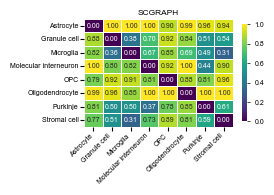

In [344]:
fig, ax = plt.subplots(figsize=(2.4, 1.4))
sns.heatmap(
    sg.consensus_df, 
    annot=True,
    annot_kws={'fontsize': 5},
    fmt=".2f",
    cbar_kws={'shrink': .9},
    cmap='viridis',
    linewidths=0.5,
    ax=ax
)
ax.tick_params(axis='both', which='major', width=.8,length=3, labelsize=6, pad=1)
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=5, width=0.5, length=2)
plt.title("SCGRAPH", fontsize=6, pad=3)
ax.set_xticks(np.arange(len(sg.consensus_df.columns)) + 0.5)
ax.set_xticklabels(sg.consensus_df.columns, rotation=45, ha='right', fontsize=5)
ax.set_yticks(np.arange(len(sg.consensus_df.index)) + 0.5)
ax.set_yticklabels(sg.consensus_df.index, rotation=0, fontsize=5)
plt.savefig('../publication_figures/scgraph_nph_cerebellum.png', dpi=300, bbox_inches='tight')
plt.show()

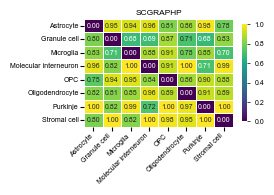

In [345]:
fig, ax = plt.subplots(figsize=(2.4, 1.4))
sns.heatmap(
    sg1.consensus_df, 
    annot=True,
    annot_kws={'fontsize': 5},
    fmt=".2f",
    cbar_kws={'shrink': .9},
    cmap='viridis',
    linewidths=0.5,
    ax=ax
)
ax.tick_params(axis='both', which='major', width=.8,length=3, labelsize=6, pad=1)
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=5, width=0.5, length=2)
plt.title("SCGRAPHP", fontsize=6, pad=3)
ax.set_xticks(np.arange(len(sg.consensus_df.columns)) + 0.5)
ax.set_xticklabels(sg.consensus_df.columns, rotation=45, ha='right', fontsize=5)
ax.set_yticks(np.arange(len(sg.consensus_df.index)) + 0.5)
ax.set_yticklabels(sg.consensus_df.index, rotation=0, fontsize=5)
plt.savefig('../publication_figures/scgraphp_nph_cerebellum.png', dpi=300, bbox_inches='tight')
plt.show()

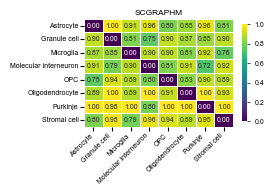

In [343]:
fig, ax = plt.subplots(figsize=(2.4, 1.4))
sns.heatmap(
    sg2.consensus_df, 
    annot=True,
    annot_kws={'fontsize': 5},
    fmt=".2f",
    cbar_kws={'shrink': .9},
    cmap='viridis',
    linewidths=0.5,
    ax=ax
)
ax.tick_params(axis='both', which='major', width=.8,length=3, labelsize=6, pad=1)
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=5, width=0.5, length=2)
plt.title("SCGRAPHM", fontsize=6, pad=3)
ax.set_xticks(np.arange(len(sg.consensus_df.columns)) + 0.5)
ax.set_xticklabels(sg.consensus_df.columns, rotation=45, ha='right', fontsize=5)
ax.set_yticks(np.arange(len(sg.consensus_df.index)) + 0.5)
ax.set_yticklabels(sg.consensus_df.index, rotation=0, fontsize=5)
plt.savefig('../publication_figures/scgraphm_nph_cerebellum.png', dpi=300, bbox_inches='tight')
plt.show()

In [252]:
sg2.consensus_df - sg.consensus_df

,B cell,CD14+ monocyte,CD16+ monocyte,CD4+ T cell,Cytotoxic T cell,Megakaryocyte,Natural killer cell,Dendritic cell,Plasmacytoid dendritic cell
B cell,0.000000,0.132146,0.181526,0.138432,0.138408,0.016620,0.115710,0.271752,0.440211
CD14+ monocyte,0.103248,0.000000,0.060814,0.067810,0.067393,-0.022790,0.038245,0.166818,0.209326
CD16+ monocyte,0.178461,0.082150,0.000000,0.144645,0.123771,0.027667,0.126281,0.217773,0.293917
CD4+ T cell,0.142593,0.104418,0.154849,0.000000,0.104216,0.031967,0.127796,0.175866,0.335086
Cytotoxic T cell,0.144224,0.105620,0.137001,0.104454,0.000000,0.031322,0.128974,0.181290,0.309042
Megakaryocyte,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Natural killer cell,0.128289,0.087425,0.141473,0.129319,0.131740,0.043542,0.000000,0.172235,0.229719
Dendritic cell,0.244023,0.168286,0.198832,0.159494,0.165386,-0.006158,0.145714,0.000000,0.281784
Plasmacytoid dendritic cell,0.462835,0.293183,0.335875,0.386839,0.364301,0.098891,0.277490,0.339630,0.000000


In [187]:
dists = (sg2.consensus_df - sg.consensus_df).to_numpy()
dists = dists[np.triu_indices(sg.consensus_df.shape[0], k=1)]

(array([ 7., 15., 13., 29., 28., 42., 67., 76., 55., 43., 21.,  9., 16.,
        13., 13.,  5.,  4.,  2.,  4.,  3.]),
 array([-0.29838749, -0.24222262, -0.18605776, -0.12989289, -0.07372803,
        -0.01756317,  0.0386017 ,  0.09476656,  0.15093142,  0.20709629,
         0.26326115,  0.31942601,  0.37559088,  0.43175574,  0.48792061,
         0.54408547,  0.60025033,  0.6564152 ,  0.71258006,  0.76874492,
         0.82490979]),
 <BarContainer object of 20 artists>)

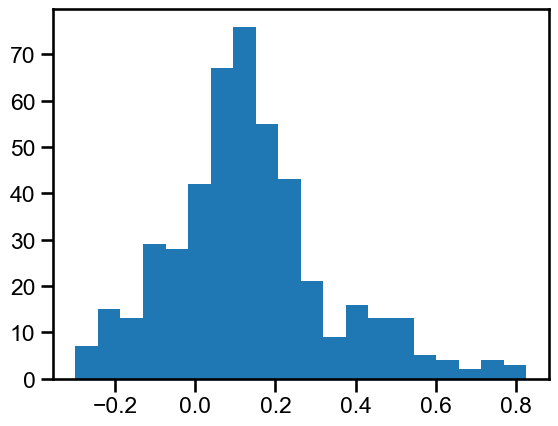

In [190]:
plt.hist(dists, bins=20)

## scGraph under ablation of distance metric

In [5]:
def fisher_poisson(m1, m2):
    return np.sum( 2 * np.abs(np.sqrt(m1) - np.sqrt(m2)) )

def fisher_multinomial(m1, m2):
    v = np.sum(np.sqrt(m1 * m2))
    v = np.clip(v, -1, 1)
    return 2 * np.arccos(v)

In [56]:
dataset = 'human_pancreas'
adata = sc.read(f'../data/{dataset}.h5ad')

In [91]:
d = runs[runs.name.str.contains(dataset) & runs.name.str.contains('respan')].iloc[0]['workdir']
adata_int = sc.read(f"{d}/save_dir/adata.h5ad")
batch_col = dataset_keys[dataset]['batch_keys'][0]
celltype_col = dataset_keys[dataset]['celltype_keys'][0]

if adata_int.X is None:
    adata_int = ad.AnnData(
        X=adata.X,
        obs=adata_int.obs,
        var=adata.var,
        uns=adata_int.uns,
        obsm=adata_int.obsm,
        varm=adata_int.varm,
        obsp=adata_int.obsp,
        varp=adata.varp,
        layers=adata.layers,
)

adata_int

AnnData object with n_obs × n_vars = 16382 × 19093
    obs: 'tech', 'celltype', 'cluster_0.2', 'cluster_0.4', 'cluster_0.6', 'cluster_0.8', 'cluster_1.0', 'cluster_1.2', 'cluster_1.4', 'cluster_1.6', 'cluster_1.8', 'cluster_2.0'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'seurat_v3_highly_variable', 'dispersions', 'dispersions_norm'
    uns: 'cluster_0.2', 'cluster_0.4', 'cluster_0.6', 'cluster_0.8', 'cluster_1.0', 'cluster_1.2', 'cluster_1.4', 'cluster_1.6', 'cluster_1.8', 'cluster_2.0', 'neighbors'
    obsm: 'X_integration', 'X_umap'
    layers: 'counts', 'orig_counts'
    obsp: 'connectivities', 'distances'

In [92]:
adata_int.obsm['X_integration']

array([[-2.881248  , -0.04026812,  1.3570049 , ..., -0.44217044,
        -0.3747244 , -0.3895266 ],
       [-4.7462926 ,  0.3270211 ,  0.7317414 , ..., -0.87386733,
         1.7769139 ,  0.37533116],
       [-4.1719484 ,  0.2223285 ,  0.9905687 , ...,  0.17333655,
         2.6678631 , -1.4066381 ],
       ...,
       [-2.704141  ,  0.43379954, -0.2293786 , ...,  0.6723683 ,
        -1.9154755 ,  0.97363955],
       [-5.4125648 ,  2.174722  , -0.6521365 , ...,  0.6086314 ,
        -0.72009695,  0.371294  ],
       [-6.9461727 ,  1.965278  , -0.76730245, ...,  0.26837778,
        -1.2721955 ,  1.0951796 ]], shape=(16382, 20), dtype=float32)

In [71]:
sg = scGraph(adata_int, batch_col, celltype_col, 'default')
sg.preprocess()
sg.process_batches()
sg.calculate_consensus()

sg1 = scGraph(adata_int, batch_col, celltype_col, 'default', metric='cosine')
sg1.preprocess()
sg1.process_batches()
sg1.calculate_consensus()

Skipped cell type t_cell, due to < 10 cells
Processing batches, calculate centroids and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 9/9 [00:01<00:00,  6.19it/s]


Skipped cell type t_cell, due to < 10 cells
Processing batches, calculate centroids and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 9/9 [00:03<00:00,  2.62it/s]


In [72]:
sg.consensus_df

,acinar,activated_stellate,alpha,beta,delta,ductal,endothelial,epsilon,gamma,macrophage,mast,quiescent_stellate,schwann
acinar,0.000000,1.000000,0.882053,0.897000,0.890406,0.728921,1.000000,0.845729,0.879224,0.949682,0.888487,1.000000,1.000000
activated_stellate,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.853854,1.000000,1.000000,1.000000,1.000000,0.323959,0.756825
alpha,0.735788,0.837936,0.000000,0.447184,0.392328,0.706106,0.816926,0.228369,0.303591,0.709691,0.531196,0.778471,0.639266
beta,0.747857,0.837774,0.446708,0.000000,0.359348,0.721682,0.818846,0.329995,0.410919,0.736630,0.546253,0.779846,0.636929
delta,0.730859,0.823571,0.373881,0.341326,0.000000,0.688633,0.802212,0.198173,0.282420,0.690341,0.459689,0.760656,0.596214
ductal,0.616896,0.861241,0.725503,0.742337,0.719528,0.000000,0.837007,0.662625,0.712918,0.803319,0.667209,0.824310,0.723826
endothelial,0.895716,0.767358,0.875811,0.877413,0.876353,0.874084,0.000000,0.887340,0.871624,0.876916,0.816807,0.729550,0.758483
epsilon,0.685415,0.817564,0.222452,0.322409,0.194912,0.628117,0.808780,0.000000,0.153927,0.682657,0.473913,0.754548,0.581724
gamma,0.724400,0.826444,0.292477,0.395842,0.286024,0.685393,0.801730,0.156618,0.000000,0.678917,0.488949,0.755454,0.595638
macrophage,0.788769,0.841244,0.724504,0.749403,0.722755,0.784345,0.818908,0.717709,0.709249,0.000000,0.471262,0.803459,0.723686


In [73]:
sg1.consensus_df

,acinar,activated_stellate,alpha,beta,delta,ductal,endothelial,epsilon,gamma,macrophage,mast,quiescent_stellate,schwann
acinar,0.000000,0.882147,0.986474,0.977055,1.000000,0.486964,0.808143,1.000000,1.000000,0.820204,0.940427,0.857893,0.871030
activated_stellate,0.731926,0.000000,0.826018,0.803582,0.811704,0.622131,0.442336,0.925184,0.834285,0.616420,0.753940,0.044304,0.178938
alpha,1.000000,1.000000,0.000000,0.663493,0.549571,0.990951,0.927694,0.330621,0.383617,0.963129,0.999378,0.990749,1.000000
beta,0.998591,0.980106,0.673366,0.000000,0.408106,1.000000,0.928814,0.652208,0.587431,1.000000,1.000000,0.959225,0.955588
delta,0.984116,0.945978,0.483166,0.348341,0.000000,0.933923,0.895997,0.221572,0.285854,0.905731,0.740059,0.925384,0.865637
ductal,0.479994,0.765640,1.000000,1.000000,0.971858,0.000000,0.695540,0.937016,0.987771,0.770715,0.782660,0.720710,0.641006
endothelial,0.698745,0.460639,0.802435,0.797811,0.802815,0.592836,0.000000,0.971491,0.803365,0.543574,0.599702,0.381782,0.365048
epsilon,0.900820,0.998819,0.295554,0.567425,0.219605,0.828265,1.000000,0.000000,0.129581,0.969938,0.902318,1.000000,0.940676
gamma,0.980220,0.970646,0.308775,0.494822,0.270005,0.945305,0.889816,0.136251,0.000000,0.871351,0.843246,0.931701,0.893573
macrophage,0.651514,0.589379,0.771639,0.791855,0.744142,0.593122,0.492609,0.864896,0.717110,0.000000,0.273659,0.546583,0.449209


In [74]:
sg.adata_consensus('X_integration')

,acinar,activated_stellate,alpha,beta,delta,ductal,endothelial,epsilon,gamma,macrophage,mast,quiescent_stellate,schwann
acinar,0.000000,0.671044,0.485870,0.516848,0.628314,0.478602,0.916234,0.645529,0.541115,0.886176,0.811929,0.645889,0.786450
activated_stellate,0.770574,0.000000,0.728547,0.722476,0.906432,0.768204,0.707521,1.000000,0.725303,0.878270,1.000000,0.426024,0.622272
alpha,0.495469,0.646979,0.000000,0.430803,0.525974,0.497269,0.774918,0.582764,0.421673,0.880940,0.888041,0.673186,0.848190
beta,0.524594,0.638588,0.428789,0.000000,0.435378,0.507559,0.833007,0.711590,0.456288,0.899457,0.850402,0.602128,0.776781
delta,0.615949,0.773819,0.505633,0.420507,0.000000,0.523986,0.821638,0.438650,0.402329,0.868735,0.769961,0.833786,0.689967
ductal,0.498316,0.696536,0.507722,0.520663,0.556523,0.000000,0.760178,0.685011,0.526581,0.922679,0.882036,0.726395,0.819013
endothelial,0.876747,0.589581,0.727155,0.785336,0.802012,0.698638,0.000000,0.824630,0.674588,0.847984,0.750201,0.574097,0.721026
epsilon,0.678687,0.915567,0.600828,0.737094,0.470440,0.691704,0.906035,0.000000,0.442257,0.861980,0.678772,0.961991,0.868918
gamma,0.610618,0.712748,0.466616,0.507292,0.463120,0.570709,0.795520,0.474680,0.000000,1.000000,0.790976,0.727499,0.836056
macrophage,1.000000,0.863067,0.974833,1.000000,1.000000,1.000000,1.000000,0.925175,1.000000,0.000000,0.663083,1.000000,0.962718


In [75]:
sg1.adata_consensus('X_integration')

,acinar,activated_stellate,alpha,beta,delta,ductal,endothelial,epsilon,gamma,macrophage,mast,quiescent_stellate,schwann
acinar,0.000000,0.719986,0.813518,0.847287,0.829076,6.146878e-01,1.000000e+00,0.637457,9.353121e-01,0.733044,0.628642,5.695803e-01,0.644703
activated_stellate,0.773389,0.000000,0.779988,0.714059,0.902642,7.981285e-01,3.900548e-01,0.974948,8.774186e-01,0.561747,0.786587,1.617736e-01,0.293891
alpha,0.935076,0.834629,0.000000,1.000000,0.862970,1.000000e+00,8.404360e-01,0.615694,8.072620e-01,0.839172,1.000000,8.102799e-01,1.000000
beta,0.973891,0.764082,1.000000,0.000000,0.530165,9.575223e-01,9.833357e-01,0.999019,8.924640e-01,0.876035,0.817903,5.622041e-01,0.715168
delta,0.980015,0.993298,0.887472,0.545218,0.000000,7.367566e-01,7.791836e-01,0.259003,5.165964e-01,0.691207,0.533923,1.000000e+00,0.449918
ductal,0.660764,0.798712,0.935216,0.895490,0.670004,1.597252e-16,6.580947e-01,0.740584,9.112887e-01,0.833972,0.808559,7.554879e-01,0.726691
endothelial,1.000000,0.363121,0.731181,0.855504,0.659176,6.122049e-01,1.716979e-16,0.644742,7.175344e-01,0.513821,0.419730,2.872082e-01,0.392960
epsilon,0.702334,1.000000,0.590171,0.957606,0.241412,7.590586e-01,7.103600e-01,0.000000,3.489891e-01,0.572554,0.351434,9.320826e-01,0.637996
gamma,0.917694,0.801445,0.689090,0.761820,0.428799,8.317745e-01,7.040182e-01,0.310785,8.749713e-17,1.000000,0.574270,7.197493e-01,0.736397
macrophage,0.719235,0.513107,0.716328,0.747796,0.573734,7.612039e-01,5.041418e-01,0.509876,1.000000e+00,0.000000,0.255237,5.725232e-01,0.507434


In [23]:
sg = scGraph(adata_int, batch_col, celltype_col, 'fisher_multinomial', metric='euclidean')
sg.preprocess()
sg.process_batches_fisher()
sg.calculate_consensus()

sg1 = scGraph(adata_int, batch_col, celltype_col, 'fisher_poisson', metric='cosine')
sg1.preprocess()
sg1.process_batches_fisher()
sg1.calculate_consensus()

Processing batches using Fisher information metric and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:00<00:00,  2.34it/s]


Processing batches using Fisher information metric and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:00<00:00,  2.37it/s]


In [24]:
sg.consensus_df

,CD14 monocyte,CD16 monocyte,DC,Early effector CD8+ T,MAIT,Megakaryocyte,Memory B,Memory CD4 T,NK,Naive B,Naive CD4 T,Naive CD8 T,Terminal effector CD8+ T,gd T,pDC
CD14 monocyte,0.000000,0.269924,0.325877,0.739905,0.762973,0.937144,0.691858,0.726519,0.746700,0.714401,0.755841,0.761984,0.759159,0.767459,0.637421
CD16 monocyte,0.271842,0.000000,0.364846,0.734725,0.752154,0.943565,0.679067,0.726297,0.729375,0.702895,0.754733,0.759910,0.744532,0.750016,0.649294
DC,0.325326,0.361613,0.000000,0.695758,0.721088,0.935249,0.598606,0.684725,0.716668,0.625444,0.719879,0.724921,0.715544,0.726933,0.550111
Early effector CD8+ T,0.733937,0.723612,0.691374,0.000000,0.322261,0.929284,0.634211,0.260505,0.388533,0.658210,0.351776,0.346405,0.259178,0.334358,0.685001
MAIT,0.770933,0.754558,0.729886,0.328287,0.000000,0.946433,0.709832,0.446303,0.346070,0.734567,0.526809,0.539664,0.223334,0.297275,0.736994
Megakaryocyte,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Memory B,0.728396,0.709872,0.631351,0.673160,0.739613,0.986363,0.000000,0.657343,0.743114,0.210110,0.659159,0.670036,0.733948,0.739700,0.590200
Memory CD4 T,0.718423,0.713136,0.678333,0.259705,0.436759,0.926473,0.617418,0.000000,0.536263,0.648286,0.233662,0.296043,0.446317,0.499910,0.676883
NK,0.759013,0.736063,0.729767,0.398162,0.348144,0.951936,0.717487,0.551277,0.000000,0.734350,0.596456,0.593574,0.270801,0.280679,0.719698
Naive B,0.762578,0.744993,0.668820,0.708395,0.776083,1.000000,0.213018,0.699842,0.771217,0.000000,0.683222,0.690435,0.769018,0.771942,0.625830


In [25]:
sg1.consensus_df

,CD14 monocyte,CD16 monocyte,DC,Early effector CD8+ T,MAIT,Megakaryocyte,Memory B,Memory CD4 T,NK,Naive B,Naive CD4 T,Naive CD8 T,Terminal effector CD8+ T,gd T,pDC
CD14 monocyte,0.000000,0.280752,0.366066,0.857650,0.831700,0.803429,0.828598,0.842599,0.853228,0.844797,0.814015,0.837829,0.826956,0.845176,0.660046
CD16 monocyte,0.310806,0.000000,0.379133,0.904656,0.885225,0.889401,0.868270,0.897323,0.888043,0.907175,0.879684,0.894657,0.879773,0.887191,0.662389
DC,0.455566,0.425884,0.000000,1.000000,1.000000,1.000000,0.934066,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.582551
Early effector CD8+ T,0.729444,0.695483,0.683963,0.000000,0.290621,0.629013,0.549260,0.196135,0.318531,0.558745,0.272290,0.266694,0.214160,0.311398,0.671176
MAIT,0.760135,0.731097,0.734742,0.312124,0.000000,0.573144,0.644121,0.370217,0.343363,0.633033,0.393418,0.416846,0.218927,0.274210,0.728648
Megakaryocyte,1.000000,1.000000,1.000000,0.922525,0.782528,0.000000,1.000000,0.896456,0.941645,0.929495,0.756754,0.807423,0.837537,0.822768,1.000000
Memory B,0.717317,0.678057,0.649494,0.560140,0.610886,0.696217,0.000000,0.539809,0.626073,0.232211,0.496465,0.507088,0.588969,0.616917,0.590575
Memory CD4 T,0.709020,0.682339,0.676403,0.194049,0.340975,0.605453,0.523379,0.000000,0.400743,0.537162,0.199567,0.229291,0.307955,0.399890,0.663764
NK,0.732433,0.688911,0.690202,0.321405,0.322534,0.648025,0.619839,0.408578,0.000000,0.620748,0.424433,0.427285,0.234219,0.272183,0.686719
Naive B,0.729738,0.708483,0.695012,0.567763,0.598830,0.642946,0.231180,0.551304,0.625058,0.000000,0.462295,0.480240,0.579950,0.610229,0.635121


In [58]:
# Calculate the distances again with cosine vs euclidean.

In [80]:
_centroid = calculate_trimmed_means(
    np.array(adata_int.obsm['X_integration']),
    adata_int.obs['celltype'],
    trim_proportion=0.05
)

In [81]:
_pairdist1 = compute_classwise_distances(_centroid, metric='euclidean')
_pairdist1

,acinar,activated_stellate,alpha,beta,delta,ductal,endothelial,epsilon,gamma,macrophage,mast,quiescent_stellate,schwann,t_cell
acinar,0.000000,4.708909,3.027769,3.205747,3.764008,3.045167,5.357721,4.147395,3.731435,6.110912,5.697544,4.220763,5.308061,4.402271
activated_stellate,4.708909,0.000000,4.540042,4.481160,5.430113,4.887798,4.137261,6.424800,5.001563,6.056396,7.017292,2.783986,4.199959,5.316857
alpha,3.027769,4.540042,0.000000,2.672058,3.150926,3.163940,4.531373,3.744143,2.907784,6.074811,6.231643,4.399148,5.724766,4.236823
beta,3.205747,4.481160,2.672058,0.000000,2.608197,3.229415,4.871048,4.571824,3.146480,6.202501,5.967517,3.934792,5.242800,4.944476
delta,3.764008,5.430113,3.150926,2.608197,0.000000,3.333929,4.804571,2.818240,2.774387,5.990645,5.403039,5.448634,4.656861,4.275834
ductal,3.045167,4.887798,3.163940,3.229415,3.333929,0.000000,4.445180,4.401061,3.631212,6.362634,6.189502,4.746855,5.527844,4.890323
endothelial,5.357721,4.137261,4.531373,4.871048,4.804571,4.445180,0.000000,5.298084,4.651843,5.847549,5.264376,3.751615,4.866487,4.006609
epsilon,4.147395,6.424800,3.744143,4.571824,2.818240,4.401061,5.298084,0.000000,3.049725,5.944061,4.763139,6.286431,5.864672,3.413064
gamma,3.731435,5.001563,2.907784,3.146480,2.774387,3.631212,4.651843,3.049725,0.000000,6.895824,5.550513,4.754068,5.642873,4.235341
macrophage,6.110912,6.056396,6.074811,6.202501,5.990645,6.362634,5.847549,5.944061,6.895824,0.000000,4.653047,6.534814,6.497762,3.757595


In [82]:
_pairdist2 = compute_classwise_distances(_centroid, metric='cosine')
_pairdist2

,acinar,activated_stellate,alpha,beta,delta,ductal,endothelial,epsilon,gamma,macrophage,mast,quiescent_stellate,schwann,t_cell
acinar,0.000000,1.000169,1.209267,1.259464,1.267383,8.545183e-01,1.293228e+00,0.908278,1.186788e+00,0.930136,0.813089,8.707000e-01,0.917433,0.860747
activated_stellate,1.000169,0.000000,1.159426,1.061425,1.379841,1.109532e+00,5.044299e-01,1.389151,1.113328e+00,0.712783,1.017376,2.472984e-01,0.418216,0.855476
alpha,1.209267,1.159426,0.000000,1.486466,1.319197,1.390166e+00,1.086876e+00,0.877269,1.024309e+00,1.064798,1.293405,1.238650e+00,1.423032,0.945532
beta,1.259464,1.061425,1.486466,0.000000,0.810448,1.331115e+00,1.271678e+00,1.423448,1.132419e+00,1.111573,1.057880,8.594242e-01,1.017707,1.399354
delta,1.267383,1.379841,1.319197,0.810448,0.000000,1.024214e+00,1.007662e+00,0.369039,6.554926e-01,0.877050,0.690579,1.528670e+00,0.640248,0.803501
ductal,0.854518,1.109532,1.390166,1.331115,1.024214,2.220446e-16,8.510668e-01,1.055218,1.156305e+00,1.058200,1.045795,1.154891e+00,1.034104,1.117656
endothelial,1.293228,0.504430,1.086876,1.271678,1.007662,8.510668e-01,2.220446e-16,0.918658,9.104564e-01,0.651970,0.542881,4.390464e-01,0.559194,0.474681
epsilon,0.908278,1.389151,0.877269,1.423448,0.369039,1.055218e+00,9.186577e-01,0.000000,4.428210e-01,0.726495,0.454547,1.424846e+00,0.907889,0.389147
gamma,1.186788,1.113328,1.024309,1.132419,0.655493,1.156305e+00,9.104564e-01,0.442821,1.110223e-16,1.268868,0.742765,1.100259e+00,1.047917,0.767846
macrophage,0.930136,0.712783,1.064798,1.111573,0.877050,1.058200e+00,6.519705e-01,0.726495,1.268868e+00,0.000000,0.330125,8.751988e-01,0.722095,0.235166


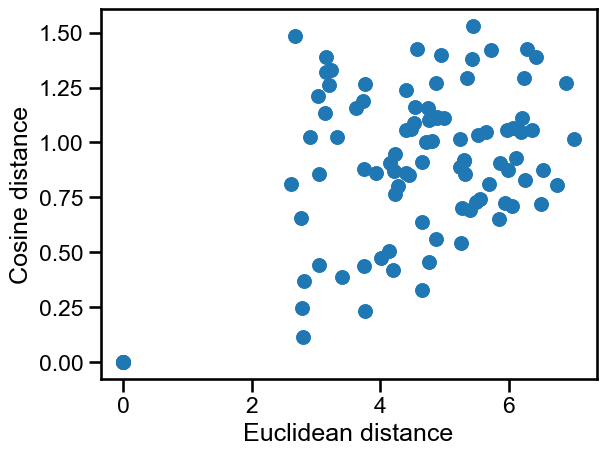

In [83]:
plt.scatter(_pairdist1.to_numpy().flatten(), _pairdist2.to_numpy().flatten())
plt.xlabel('Euclidean distance')
plt.ylabel('Cosine distance')
plt.show()

In [31]:
adata_int.obsm['X_integration'].shape

(19202, 20)

## Difference in distances between SCGRAPH and variants

In [312]:
scgraphp_vs = dict()
scgraphm_vs = dict()

for d in dataset_keys.keys():
    print(d)
    adata = sc.read(f'../data/{d}.h5ad')
    batch_col = dataset_keys[d]['batch_keys'][0]
    celltype_col = dataset_keys[d]['celltype_keys'][0]
    
    sg = scGraph(adata, batch_col, celltype_col, 'default')
    sg.preprocess()
    sg.process_batches()
    sg.calculate_consensus()
    
    sg1 = scGraph(adata, batch_col, celltype_col, 'fisher_poisson')
    sg1.preprocess()
    sg1.process_batches_fisher()
    sg1.calculate_consensus()
    
    sg2 = scGraph(adata, batch_col, celltype_col, 'fisher_multinomial')
    sg2.preprocess()
    sg2.process_batches_fisher()
    sg2.calculate_consensus()
    
    dists = (sg1.consensus_df - sg.consensus_df).to_numpy()
    mask = ~np.eye(dists.shape[0], dtype=bool)
    dists = dists[mask]
    scgraphp_vs[d] = dists
    
    dists = (sg2.consensus_df - sg.consensus_df).to_numpy()
    mask = ~np.eye(dists.shape[0], dtype=bool)
    dists = dists[mask]
    scgraphm_vs[d] = dists

scib_sim1
Processing batches, calculate centroids and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:03<00:00,  1.65it/s]


Processing batches using Fisher information metric and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:01<00:00,  5.35it/s]


Processing batches using Fisher information metric and pairwise distances


...

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:05<00:00,  2.87s/it]


Processing batches using Fisher information metric and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:03<00:00,  1.51s/it]


Processing batches using Fisher information metric and pairwise distances


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:03<00:00,  1.56s/it]


In [313]:
with open('../results/spreadsheets/scgraphp_diff.pkl', 'wb') as f:
    pickle.dump(scgraphp_vs, f)
    
with open('../results/spreadsheets/scgraphm_diff.pkl', 'wb') as f:
    pickle.dump(scgraphm_vs, f)

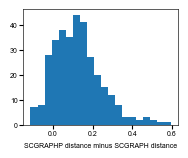

In [314]:
fig, ax = plt.subplots(figsize=(2, 1.5))
plt.hist(scgraphm_vs['human_retina_organoid_tissue'], bins=20)
plt.xlabel('SCGRAPHP distance minus SCGRAPH distance', fontsize=5)
ax.tick_params(axis='both', which='major', width=.8,
                   length=3, 
                   labelsize=5,
                   pad=1)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)
plt.show()

In [227]:
np.concatenate(list(scgraphm_vs.values()))

array([-0.00176866, -0.02492818,  0.        , ...,  0.11532166,
        0.04830715,  0.05273561], shape=(5577,))

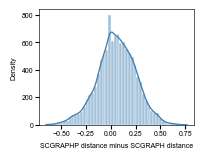

In [325]:
fig, ax = plt.subplots(figsize=(2, 1.5))

data = np.concatenate(list(scgraphp_vs.values()))

sns.histplot(
    data, 
    bins=50, 
    kde=True, 
    ax=ax, 
    color='steelblue',
    edgecolor='white',
    linewidth=0.3,
    line_kws={'linewidth': 1} # Styling for the KDE line
)

plt.xlabel('SCGRAPHP distance minus SCGRAPH distance', fontsize=5)
plt.ylabel('Density', fontsize=5) # Note: y-axis is now Density

# Apply your existing spine and tick styling
ax.tick_params(axis='both', which='major', width=.8, length=3, labelsize=5, pad=1)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)
plt.savefig('../publication_figures/scgraphp_density.png', dpi=300, bbox_inches='tight')
plt.show()

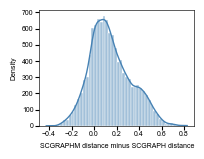

In [326]:
fig, ax = plt.subplots(figsize=(2, 1.5))

data = np.concatenate(list(scgraphm_vs.values()))

sns.histplot(
    data, 
    bins=50, 
    kde=True, 
    ax=ax, 
    color='steelblue',
    edgecolor='white',
    linewidth=0.3,
    line_kws={'linewidth': 1} # Styling for the KDE line
)

plt.xlabel('SCGRAPHM distance minus SCGRAPH distance', fontsize=5)
plt.ylabel('Density', fontsize=5) # Note: y-axis is now Density

# Apply your existing spine and tick styling
ax.tick_params(axis='both', which='major', width=.8, length=3, labelsize=5, pad=1)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)
plt.savefig('../publication_figures/scgraphm_density.png', dpi=300, bbox_inches='tight')
plt.show()

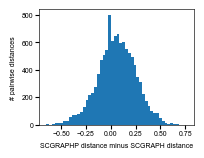

In [321]:
fig, ax = plt.subplots(figsize=(2, 1.5))
plt.hist(np.concatenate(list(scgraphp_vs.values())), bins=50)
plt.xlabel('SCGRAPHP distance minus SCGRAPH distance', fontsize=5)
plt.ylabel('# pairwise distances', fontsize=5)
ax.tick_params(axis='both', which='major', width=.8,
                   length=3, 
                   labelsize=5,
                   pad=1)
for spine in ax.spines.values():
    spine.set_linewidth(0.45)
plt.show()